<div style="border:1px solid #d8dee9; border-radius:8px; padding:16px 18px; background:#fbfcff; margin-bottom:14px;">
  <h1 style="margin:0 0 6px 0;">CraTEs Analysis Pipeline</h1>
  <h5 style="margin:0 0 6px 0;">07.04. - 07.08.2026 Master 1 Internship at Inserm Nice, in lab Gael Christofari.</h5>
  <p style="margin:0; color:#586069;"><strong>Author:</strong> Vinzent Aschir &nbsp; | &nbsp; <strong>Notebook:</strong> R kernel</p>
</div>

<details>
<summary><strong>Notebook metadata carried over from the Quarto source</strong></summary>

- Title: `CraTEs Analysis Pipeline`
- Format target in the source qmd: HTML with table of contents
- Execution settings in the source qmd: `echo: true`, `error: true`

</details>

## Pipeline overview

This notebook is an improved implementation for the craTEs pipeline, first used for recreation of the paper experiment. 

---

## 0 · Setup

example from the craTEs paper to get an understanding of the usage.

### ── Working directory ──

In [75]:
find_project_dir <- function(start = getwd()) {
  current <- normalizePath(start, mustWork = TRUE)
  repeat {
    if (file.exists(file.path(current, "scripts", "craTEs_own_function.R")) && dir.exists(file.path(current, "R"))) {
      return(current)
    }
    parent <- dirname(current)
    if (identical(parent, current)) {
      stop("Could not locate the craTEs repository root.", call. = FALSE)
    }
    current <- parent
  }
}

project_dir <- find_project_dir()
setwd(project_dir)

### ── Libraries ──

In [76]:
# libraries
library(Matrix)
library(data.table)
library(parallel)
library(dplyr)
library(ggplot2)
library(ggVennDiagram)
library(ggtext)

# craTEs library
library(craTEs)
ls("package:craTEs")

[1] "estimate_rmse_crossval"         "estimateRMSE"                  
 [3] "get_pseudocounts"               "getActivities"                 
 [5] "getSignifActivities"            "N_from_tsv"                    
 [7] "plot_signif_subfams"            "plot_signif_subfams_functional"
 [9] "plotActivities"                 "preprocess_E_N_for_activities" 
[11] "pval_from_fstat"                "row_center"                    
[13] "split_N_to_functional"

### ── Helper functions ──

**Local craTEs overrides.** The functions sourced from `local_craTEs_extension/` are backward-compatible because they keep the same function names and call style used by the package (`getActivities()`, `getSignifActivities()`, `preprocess_E_N_for_activities()`). They improve the package versions for these notebooks by adding hg38-aware preprocessing/exon-length handling, stricter matrix/name checks, and clearer diagnostics while preserving the original hg19 workflow.

In [77]:
source("scripts/te_trend_classification_f.R")
source("scripts/craTEs_own_function.R")
source("scripts/own_mapping_f.R")
source("local_craTEs_extension/getActivities.R")
source("local_craTEs_extension/getSignifActivities.R")
source("local_craTEs_extension/preprocess_E_N_for_activities_hg38.R")

[1] "sourcing the custom function from crates"


### ── Global Variables ──


`handling` controls how duplicate gene rows are resolved throughout the pipeline.
  It is set once here so the same strategy applies consistently to both E and N.
- `discard` = All duplicates are removed rather than aggregated

- `Max Sum` = 	retain duplicates with the highest total expression across samples

- `Max Variance` =	retain duplicates with the highest expression variance across samples

- `Sum` = 		aggregate all duplicate rows elementwise 

- `Average` = 	average all duplicate rows elementwise


- `identical` = 	collapse only rows with that are exact duplicates throught all the gene counts


In [78]:
handling <- "discard"

# Global reference switch: use "Hg38" for the current TE-Seq workflow or "Hg19" for GRCh37/Hg19 N matrices.
reference_genome <- "Hg38"  # "Hg19" 

# N matrix selection within the selected reference genome.
n_matrix_key <- "counted_100kb" #"weighted_250kb"

# Leave NULL to infer from N_path: N_c_* = counted, N_w_* = weighted.
analysis_mode <- NULL

In [79]:
# log_dir is created once E_path and N_path are known.
log_dir <- NULL

---
## 1 · Expression Matrix E


Duplicate gene names are checked, resolved with `method = handling` and `threshold = 10`, and then the Excel date-mangled symbols are repaired before mapping.

### ── E - Gene Expression Matrix - TESeq - Senescene 1 ──

> E -  Expression matrix for sensecence cells from [TE-Seq paper](https://link.springer.com/article/10.1186/s13100-025-00381-w#data-availability).


The paper provides a final experiment specific count table with already median-ratio normalised counts. However the raw counts from this paper are taken from [archs4 archive](https://archs4.org/data) under the accession number GSM8595549 as the expected input for craTEs.

In [80]:

## E - Expression matrix
# Read ARCHS4 gene count table
# https://archs4.org/data
# GSM8595549
E_path <- "./data/Hg38/E_Senescene_TE_Seq_raw.tsv"
E <- fread(E_path)

E_genes <- E[[1]]
E <- as.matrix(E[, -1])
rownames(E) <- E_genes


we use the metadata  GSE280365, querried via R API from the online GEO database to translate sample numbers to meaningful abreviation.

In [81]:
# Load GEO metadata from a local cache when possible
geo_metadata_cache_path <- "./data/Hg38/GSE280365_sample_metadata.tsv"


# Read the raw count table before selecting GEO sample columns
E_dt <- fread(E_path)
E_genes <- E_dt[[1]]

# Keep only GSM sample columns
sample_cols <- grep("^GSM", colnames(E_dt), value = TRUE)

E <- as.matrix(E_dt[, ..sample_cols])
rownames(E) <- E_genes

# Download only the series metadata if the cache is missing
if (file.exists(geo_metadata_cache_path)) {
  meta <- fread(geo_metadata_cache_path)
  } else {
  library(GEOquery)
  gse <- getGEO("GSE280365", GSEMatrix = TRUE, getGPL = FALSE)
  meta <- as.data.table(Biobase::pData(gse[[1]]))
  meta <- meta[, .(geo_accession, title)]
  fwrite(meta, geo_metadata_cache_path, sep = "\t")}

sample_meta <- meta[ geo_accession %in% sample_cols, .(geo_accession, title)]

# Add meaningful sample names
sample_meta[, condition := fifelse(grepl("proliferating", title), "PRO",
                           fifelse(grepl("early senescence", title), "ESEN",
                           fifelse(grepl("late senescence", title), "LSEN", NA_character_)))]

sample_meta[, replicate := sub(".*replicate ", "", title)]
sample_meta[, sample_name := paste0(condition, replicate)]

# Order metadata like matrix columns
sample_meta <- sample_meta[match(sample_cols, geo_accession)]

# Rename columns
colnames(E) <- sample_meta$sample_name

# Checks
dim(E)
colnames(E)
head(E[, 1:4])
all(E == round(E), na.rm = TRUE)


[1] 67186    12

[1] "PRO1"  "PRO2"  "PRO3"  "PRO4"  "ESEN1" "ESEN2" "ESEN3" "ESEN4" "LSEN1"
[10] "LSEN2" "LSEN3" "LSEN4"

,PRO1,PRO2,PRO3,PRO4
TSPAN6,648,563,1343,1621
TNMD,0,0,0,0
DPM1,326,237,709,1100
SCYL3,164,146,335,597
C1ORF112,255,314,507,770
FGR,7,2,6,6


[1] TRUE

The TE-Seq paper provides a final expression count table of repeats and Genes combined. 
However, these counts are already median-ratio normalised and cannot be inverted to raw counts. 
For an detailed analysis of the final result paper dataset compared to the querried archs4 raw counts follow: [TE_Seq_raw_vs_normalised.ipynb](exploratory/TE_Seq_raw_vs_normalised/TE_Seq_raw_vs_normalised.ipynb)

In [82]:
# # load preprocessed
# project_dir <- "."
# setwd(project_dir)
# data_dir <- file.path(project_dir, "data", "Hg38")

# related <- fread(file.path(data_dir, "E_TE-Seq_prep_results.tsv"))
# related <- related[gene_or_te == "gene"]

# #extract only target rows 
# sample_cols <- c(paste0("PRO", 1:4), paste0("ESEN", 1:4), paste0("LSEN", 1:4))
# related_counts <- as.matrix(related[, ..sample_cols])
# storage.mode(related_counts) <- "double"
# rownames(related_counts) <- related$gene_id

# E <-  resolve_duplicates(related_counts, method = "identical")
# E_path = E_path <- "./data/Hg38/E_TE-Seq_prep_results.tsv"

###  ── Count Check  ── 

In [83]:
count_table_to_check <- as.matrix(E)
storage.mode(count_table_to_check) <- "double"

integer_tolerance <- sqrt(.Machine$double.eps)
non_integer_mask <- is.finite(count_table_to_check) &
  abs(count_table_to_check - round(count_table_to_check)) > integer_tolerance

non_integer_idx <- which(non_integer_mask, arr.ind = TRUE)

if (nrow(non_integer_idx) == 0) {
  non_integer_entries <- data.frame(
    gene = character(),
    sample = character(),
    value = numeric(),
    stringsAsFactors = FALSE
  )
} else {
  non_integer_entries <- data.frame(
    gene = rownames(count_table_to_check)[non_integer_idx[, "row"]],
    sample = colnames(count_table_to_check)[non_integer_idx[, "col"]],
    value = count_table_to_check[non_integer_idx],
    stringsAsFactors = FALSE
  )
}

cat(sprintf(
  "Non-integer entries: %d / %d (%.4f%%)\n",
  nrow(non_integer_entries),
  length(count_table_to_check),
  100 * nrow(non_integer_entries) / length(count_table_to_check)
))
cat(sprintf("Affected genes: %d\n", length(unique(non_integer_entries$gene))))
cat(sprintf("Affected samples: %d\n", length(unique(non_integer_entries$sample))))

max_entries_to_print <- 200
if (nrow(non_integer_entries) == 0) {
  cat("All count entries are integer-like within tolerance.\n")
} else if (nrow(non_integer_entries) <= max_entries_to_print) {
  print(non_integer_entries)
} else {
  cat(sprintf(
    "Showing first %d entries. Full table is stored in non_integer_entries.\n",
    max_entries_to_print
  ))
  print(utils::head(non_integer_entries, max_entries_to_print))
}


Non-integer entries: 0 / 806232 (0.0000%)
Affected genes: 0
Affected samples: 0
All count entries are integer-like within tolerance.


### ── Duplication Check ──

the raw input may contain already duplicated gene names.

Two-step duplicate handling:
  1. `duplicate_stats()` audits how many rows share the same gene name.

In [84]:
duplicate_stats(rownames(E),E)

mapped_id,count,positions,row_sum,row_var
<chr>,<int>,<chr>,<chr>,<chr>
AADACL2,2,"17600,48648","5,3","2,0"
AADACL2-AS1,2,"38235,48862","0,9","0,1"
AATF,2,"56108,56393","36379,545","610905,2600"
ABCB10P1,3,"54883,58792,59182","0,0,0","0,0,0"
ABCB10P3,2,"48414,60116","5,0","0,0"
ABCB10P4,3,"47355,54953,59661","0,0,0","0,0,0"
ABCB11,2,"1238,56784","16,3","5,1"
ABCC1,2,"2785,57979","42929,94022","2288237,17908625"
ABCC6,2,"1923,55814","108,760","21,556"


  2. `resolve_duplicates()` collapses them using the strategy in `handling`.

In [85]:
# E = resolve_duplicates(E, method = "sum") # one suggested by TE-SEq 
# E_id = resolve_duplicates(related_counts, method = "identical")
E = resolve_duplicates(E, method = "discard") # one as default in craTEs.

[resolve_duplicates] Method 'discard': 2359 duplicate groups (6997 rows) removed.



The TE-seq pipeline aggregated their raw data through rowwise `sum` aggregating different Isoforms, and respecting multi-locus-annotation> However [TE_Seq_raw_vs_normalised.ipynb](exploratory/TE_Seq_raw_vs_normalised/TE_Seq_raw_vs_normalised.ipynb) concluded to aggregate the rather small amount of duplicates by `discard`, which aligns with the standard procedures of the craTEs pipeline. 

  3. If the input matrix contains a `Source` column, `resolve_duplicates()` reads it before duplicate resolution, removes it from the count matrix, and uses it to decide how `pre_mapped` rows should compete with translated mappings. By default, `pre_mapped = "pre-mapped"` keeps raw Ensembl IDs as the representative rows within duplicate groups; `pre_mapped = "same"` treats them like other mappings, and `pre_mapped = "unmapped"` drops them before resolving duplicates.

### ── Excel-naming Check ──

when opening Gene names in Excel, Genenames like MARCH1 are misinterpreted to datas: 1-Mar and therefore not foundable in databasis anymore.

In [86]:
gene_ids <- transform_excel_dates(rownames(E)) 
rownames(E) <- gene_ids
duplicate_stats(rownames(E),E)

$duplicate_groups
[1] 0

$affected_rows
[1] 0

$redundant_rows
[1] 0

$table
NULL

no excel naming problem in this dataset. 


---

## 2 · N - Count-Association Matrix 



### ── Load & reshape ──
N is the gene × TE-subfamily co-occurrence matrix. 
Each cell encodes how many times promoters of a given gene are associated with a given TE subfamily. It drives the linear model that infers TE activities from gene expression.


In [87]:
# # Different N matrices you can use:
#
# Historically this notebook switched matrices by commenting/uncommenting N_path lines.
# The choices are kept here as background, but the active selection is now controlled
# by the global parameters in section 0:
#   reference_genome <- "Hg38" or "Hg19"
#   n_matrix_key <- "weighted_250kb" or "counted_100kb"
#   analysis_mode <- NULL  # inferred from N_path unless explicitly set
#
# # Hg19:
#   1. N counted, L = 100kb, from CraTEs_paper
#      reference_genome <- "Hg19"; n_matrix_key <- "counted_100kb"
#      N_path would be ./data/Hg19/N_c_100_Hg19_craTEs.tsv
#
#   2. N weighted, L = 2.5e5 kb, from CraTEs_paper
#      https://zenodo.org/records/8117257
#      reference_genome <- "Hg19"; n_matrix_key <- "weighted_250kb"
#      N_path would be ./data/Hg19/N_w_2.5e5_Hg19_craTEs.tsv
#
# # Hg38:
#   1. N counted, L = 100kb, from CraTEs_paper
#      https://zenodo.org/records/10390247
#      reference_genome <- "Hg38"; n_matrix_key <- "counted_100kb"
#      N_path would be ./data/Hg38/N_c_100_Hg38_craTEs.tsv
#
#   2. N weighted, L = 2.5e5 kb, from CraTEs_paper
#      https://zenodo.org/records/10390262
#      reference_genome <- "Hg38"; n_matrix_key <- "weighted_250kb"
#      N_path would be ./data/Hg38/N_w_2.5e5_Hg38_craTEs.tsv

# Active matrix catalog used by the parameter-based selector below.
n_matrix_catalog <- list(
  Hg19 = list(
    counted_100kb = "./data/Hg19/N_c_100_Hg19_craTEs.tsv",
    weighted_250kb = "./data/Hg19/N_w_2.5e5_Hg19_craTEs.tsv"
  ),
  Hg38 = list(
    counted_100kb = "./data/Hg38/N_c_100_Hg38_craTEs.tsv",
    weighted_250kb = "./data/Hg38/N_w_2.5e5_Hg38_craTEs.tsv"
  )
)

reference_genome <- normalize_reference_genome(reference_genome)

if (!reference_genome %in% names(n_matrix_catalog)) {
  stop(sprintf("No N matrix catalog entry for reference_genome = '%s'.", reference_genome), call. = FALSE)
}
if (!n_matrix_key %in% names(n_matrix_catalog[[reference_genome]])) {
  stop(
    sprintf(
      "Unknown n_matrix_key '%s' for %s. Available keys: %s",
      n_matrix_key,
      reference_genome,
      paste(names(n_matrix_catalog[[reference_genome]]), collapse = ", ")
    ),
    call. = FALSE
  )
}

N_path <- n_matrix_catalog[[reference_genome]][[n_matrix_key]]
reference_settings <- validate_reference_n_settings(
  reference_genome = reference_genome,
  N_path = N_path,
  analysis_mode = analysis_mode
)

analysis_mode <- reference_settings$analysis_mode
org <- reference_settings$org
mapping_primary_mart <- primary_mart_for_reference_genome(reference_genome)

In [88]:
## N - gene / TE subfamily - Count Association matrix

n_loaded <- load_count_association_matrix(N_path)
N <- n_loaded$N
genes_N <- n_loaded$genes_N

selected_results_dir <- if (exists("E_path")) {
  derive_activity_results_dir(
    E_path = E_path,
    N_path = N_path,
    results_parent = file.path(getwd(), "results")
  )
} else {
  NA_character_
}

cat(sprintf("Reference genome: %s\n", reference_genome))
cat(sprintf("N matrix: %s\n", N_path))
cat(sprintf("Analysis mode: %s\n", analysis_mode))
cat(sprintf("Mapping primary mart: %s\n", mapping_primary_mart))
cat(sprintf("N dimensions: %d genes x %d TE subfamilies\n", nrow(N), ncol(N)))
cat(sprintf("Result directory: %s\n", selected_results_dir))

Reference genome: Hg38
N matrix: ./data/Hg38/N_c_100_Hg38_craTEs.tsv
Analysis mode: counted
Mapping primary mart: current
N dimensions: 19839 genes x 1076 TE subfamilies
Result directory: /Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs


In [89]:
head(rownames(N))

[1] "ENSG00000000003" "ENSG00000000005" "ENSG00000000419" "ENSG00000000457"
[5] "ENSG00000000460" "ENSG00000000938"

### ── Diagnostics-N ──

In [90]:
#duplicated genes: 
N_dub_stat = duplicate_stats(rownames(N))
sprintf("We have %d redundant duplicated Gene-rows in N in duplicated groups of %d ", N_dub_stat$redundant_rows, N_dub_stat$duplicate_groups)

# how dense is our N matrix? 
sprintf("the amount of 0 vals in the N matrix is %.2f%%", 100 * mean(N == 0))

[1] "We have 0 redundant duplicated Gene-rows in N in duplicated groups of 0 "

[1] "the amount of 0 vals in the N matrix is 92.86%"

---

## 3 · Gene ID Mapping Cache


E stores HGNC gene symbols, while N is indexed by Ensembl gene IDs.
The full server-dependent mapping procedure now lives in `scripts/gene_mapping.Rmd`, where the original BioMart, `org.Hs.eg.db`, and `mygene` heading structure is preserved as a rendered mapping report.

The notebook uses the cached TSV by default, because BioMart and MyGene server access can otherwise block every downstream step.
This section therefore only prepares the cache paths, optionally rebuilds the cache, loads the TSV, and reconstructs the objects expected by section 4.


### ── 3.1. Cache path and gene-name export ──

The cache name follows the active E and N inputs selected above.
The temporary gene-name TSVs are small handoff files for the Rmd rebuild script; they keep the expensive mapping step independent from the rest of the notebook.

In [91]:
# ── Cached mapping paths and gene-name extraction ──────────────────────────────
# The mapping cache name follows the active E_path and N_path selected above.
# reference_genome and n_matrix_key choose N_path in section 2.

if (!exists("E_path")) {
  stop("E_path is not defined. Set E_path in the active E loading cell before section 3.")
}
if (!exists("N_path")) {stop("N_path is not defined. Set N_path in the active N loading cell before section 3.")}

results_dir <- derive_activity_results_dir(
  E_path = E_path,
  N_path = N_path,
  results_parent = file.path(getwd(), "results")
)
figures_dir <- file.path(results_dir, "figures")
log_dir <- file.path(results_dir, "log")

dir.create(results_dir, showWarnings = FALSE, recursive = TRUE)
dir.create(figures_dir, showWarnings = FALSE, recursive = TRUE)
dir.create(log_dir, showWarnings = FALSE, recursive = TRUE)

options(crates.figures_dir = figures_dir, crates.log_dir = log_dir)
options(device = function(...) {grDevices::pdf(file = file.path(log_dir, "Rplots.pdf"), ...)})

mapping_inputs <- prepare_mapping_cache_inputs(
  E_path = E_path,
  N_path = N_path,
  gene_ids = gene_ids,
  genes_N = genes_N
)

mapping_cache_path <- mapping_inputs$mapping_cache_path
mapping_report_path <- mapping_inputs$mapping_report_path
mapping_status_path <- mapping_inputs$mapping_status_path
e_gene_names_path <- mapping_inputs$e_gene_names_path
n_gene_names_path <- mapping_inputs$n_gene_names_path
mapping_dir <- dirname(mapping_cache_path)

results_dir
mapping_cache_path
mapping_report_path


[1] "/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs"

[1] "/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/mapping/map_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs.tsv"

[1] "/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/mapping/report_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs.html"

### ── 3.2. Optional mapping rebuild report ──

For rebuilding the mapping, an automated call of [scripts/gene_mapping.Rmd](scripts/gene_mapping.Rmd) is provided below. The rebuild uses `mapping_primary_mart`, which is `current` for Hg38 and `grch37` for Hg19.

In [92]:
# List available Ensembl archives when BioMart is reachable.
# If the server call fails, continue silently so cached notebook runs are not interrupted.
archives <- tryCatch(
  biomaRt::listEnsemblArchives(),
  error = function(e) NULL
)

if (!is.null(archives)) {
  archives[, c("name", "date", "url", "version")]
}

name,date,url,version
<chr>,<chr>,<chr>,<chr>
Ensembl GRCh37,Feb 2014,https://grch37.ensembl.org,GRCh37
Ensembl 116,Jun 2026,https://jun2026.archive.ensembl.org,116
Ensembl 115,Sep 2025,https://sep2025.archive.ensembl.org,115
Ensembl 114,May 2025,https://may2025.archive.ensembl.org,114
Ensembl 113,Oct 2024,https://oct2024.archive.ensembl.org,113
Ensembl 112,May 2024,https://may2024.archive.ensembl.org,112
Ensembl 111,Jan 2024,https://jan2024.archive.ensembl.org,111
Ensembl 110,Jul 2023,https://jul2023.archive.ensembl.org,110
Ensembl 109,Feb 2023,https://feb2023.archive.ensembl.org,109


The rebuild command is intentionally commented during normal notebook runs.
Uncomment it only when server access is available, run it once, then restart the kernel and return to the cached workflow.
The rendered HTML report is saved beside the TSV and records the full mapping process.

In [93]:
# # ── Manual rebuild command ──────────────────────────────────────────────
# # Run this cell when BioMart/MyGene servers are reachable and the cached TSV
# # should be rebuilt. Skip this cell during normal cached notebook runs.

# source("scripts/own_mapping_f.R")

# mapping_inputs <- ensure_mapping_cache_inputs(
#   E_path = E_path,
#   N_path = N_path,
#   gene_ids = gene_ids,
#   genes_N = genes_N,
#   mapping_inputs = if (exists("mapping_inputs")) mapping_inputs else NULL
# )

# mapping_cache_path <- mapping_inputs$mapping_cache_path
# mapping_report_path <- mapping_inputs$mapping_report_path
# mapping_status_path <- mapping_inputs$mapping_status_path
# e_gene_names_path <- mapping_inputs$e_gene_names_path
# n_gene_names_path <- mapping_inputs$n_gene_names_path
# mapping_primary_mart <- primary_mart_for_reference_genome(reference_genome)

# render_gene_mapping_script <- normalizePath("scripts/render_gene_mapping.R", mustWork = TRUE)

# rebuild_output <- system2(
#   "Rscript",
#   args = c(
#     "--vanilla", render_gene_mapping_script,
#     "--e-gene-names", e_gene_names_path,
#     "--n-gene-names", n_gene_names_path,
#     "--out", mapping_cache_path,
#     "--primary-mart", mapping_primary_mart,
#     "--mirror", "www"),
#   stdout = TRUE,
#   stderr = TRUE)

# #eroor handling
# cat(paste(rebuild_output, collapse = "\n"), "\n")
# rebuild_status <- attr(rebuild_output, "status")
# if (is.null(rebuild_status)) rebuild_status <- 0L

# if (as.integer(rebuild_status) != 0L) {
#   stop(sprintf("Mapping rebuild failed with exit status %d.", as.integer(rebuild_status)), call. = FALSE)}

# if (!file.exists(mapping_cache_path)) {
#   stop(
#     mapping_cache_missing_message(
#       mapping_cache_path,
#       mapping_report_path
#     ),
#     call. = FALSE)}

# sprintf("Mapping cache ready: %s", mapping_cache_path)


### ── 3.3. Load cached mapping ──


In [94]:
# ── Load cached mapping ─────────────────
if (!file.exists(mapping_cache_path)) {
  stop(
    mapping_cache_missing_message(
      mapping_cache_path,
      mapping_report_path
    ),
    call. = FALSE)}

mapping_cache <- data.table::fread(mapping_cache_path, sep = "\t")

required_mapping_cols <- c(
  "hgnc_symbol",
  "ensembl_gene_id",
  "gene_biotype",
  "mapping_source",
  "in_N")

missing_mapping_cols <- setdiff(required_mapping_cols, colnames(mapping_cache))
if (length(missing_mapping_cols) > 0) {
  stop(paste(
    "Cached mapping is missing required columns:",
    paste(missing_mapping_cols, collapse = ", ")))}

if ("mapping_reference_genome" %in% colnames(mapping_cache)) {
  cache_reference_genomes <- unique(as.character(mapping_cache$mapping_reference_genome))
  cache_reference_genomes <- cache_reference_genomes[!is.na(cache_reference_genomes) & cache_reference_genomes != ""]
  if (length(cache_reference_genomes) > 0 && !all(cache_reference_genomes == reference_genome)) {
    stop(
      sprintf(
        "Cached mapping reference genome (%s) does not match active reference_genome (%s).",
        paste(cache_reference_genomes, collapse = ", "),
        reference_genome
      ),
      call. = FALSE
    )
  }
}

mapping_cache[, hgnc_symbol := as.character(hgnc_symbol)]
mapping_cache[, ensembl_gene_id := as.character(ensembl_gene_id)]
mapping_cache[ensembl_gene_id == "", ensembl_gene_id := NA_character_]

map_combined <- setNames(
  mapping_cache$ensembl_gene_id,
  mapping_cache$hgnc_symbol)

# Keep the active E gene order and names, matching the previous section 3 output.
map_combined <- map_combined[gene_ids]

biotype_combined <- mapping_cache %>%
  filter(!is.na(ensembl_gene_id), !is.na(gene_biotype), gene_biotype != "") %>%
  dplyr::select(ensembl_gene_id, gene_biotype) %>%
  distinct(ensembl_gene_id, gene_biotype)

unmapped_final <- gene_ids[is.na(map_combined[gene_ids])]

mapped_only <- map_combined[!is.na(map_combined)]
ensembl_to_symbol <- setNames(names(mapped_only), unname(mapped_only))

sprintf(
  "Loaded cached mapping for %d E genes from %s",
  nrow(mapping_cache),
  mapping_cache_path)

[1] "Loaded cached mapping for 60189 E genes from /Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/mapping/map_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs.tsv"

### ── 3.4. Cached mapping diagnostics ──

We analyse here only the resulted mapping we obtained through the [scripts/gene_mapping.Rmd](scripts/gene_mapping.Rmd) and a detailed data specific mapping pdf report can be found in the mapping location. 

Detailed BioMart, OrgDb and MyGene diagnostics are now documented in these gene_mapping.Rmd report. and its mapping report details, html details are stored with the mapping. The notebook only verifies that the loaded cache overlaps N and contains the expected biotype information.

In [95]:
# Location of the mapping analysis of this dataset combination:

mapping_dir_rel <- sub(
  paste0("^", normalizePath(getwd(), winslash = "/"), "/"),
  "",
  normalizePath(dirname(mapping_cache_path), winslash = "/"))
  
print(mapping_dir_rel)

[1] "results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/mapping"


The mapping is so far not bijective, and contains some duplicates. 

In [96]:
# ── Cached mapping diagnostics ───────────────────────────────────────────
sprintf(
  "%d of %d genes (%.2f%%) could not be mapped",
  length(unmapped_final),
  length(gene_ids),
  100 * length(unmapped_final) / length(gene_ids)
)

duplicate_stats(unname(map_combined[!is.na(map_combined)]),  include_table = FALSE)

[1] "88 of 60189 genes (0.15%) could not be mapped"

$duplicate_groups
[1] 130

$affected_rows
[1] 265

$redundant_rows
[1] 135

  #### ── Unmapped Genes ──

In [97]:
  # ── Unmapped Genes ─────────────────────────────────────────

classes <- classify_unmapped(unmapped_final)
unmapped_class_summary <- summarise_unmapped_classes(classes)
unmapped_class_summary

class,n
<chr>,<int>
LOC,0
SNORD,0
FLJ,0
LINC,31
KIAA,0
MIR,1
other,56


xLOC = no Gene ID assigned yet 
long intergenic non-protein coding RNA 
SNORD = ncRNAs
FLJ = clone-based names (ncRNA)

<hr style="border: none; border-top: 2px dashed #999; height: 0;">

## 4 · Map Application, Filtering

Apply mapping to E and filter to protein-coding genes

This step applies the combined symbol-to-Ensembl mapping back to E, drops unmapped rows, and checks duplicates again. The protein-coding filter is then applied, because the paper analysis focuses protein-genes.

`apply_mapping_to_expression()` is sourced from the custom helper file and keeps the remapping step in one place. If the loaded mapping table contains a source column and at least one row is marked `pre-mapped` or `pre_mapped`, the helper adds a `Source` column to `E_mapped`; otherwise it returns a plain count matrix. `resolve_duplicates()` then reads that optional `Source` column and removes it before aggregating counts.

In [98]:
# ── Apply Mapping to E ────────────────────────────────────────────
E_mapped <- apply_mapping_to_expression(
  E,
  mapping = mapping_cache,
  gene_ids = gene_ids)

[apply_mapping_to_expression] Added 'Source' column for 22451 pre-mapped rows.



#### ── Duplicate Resolvement ──

the handling of duplicates is defined globally and can be: 
- `discard` = All duplicates are removed rather than aggregated

- `Max Sum` = 	retain duplicates with the highest total expression across samples

- `Max Variance` =	retain duplicates with the highest expression variance across samples

- `Sum` = 		aggregate all duplicate rows elementwise 

- `Average` = 	average all duplicate rows elementwise
- `identical` = 	collapse only rows with that are exact duplicates throught all the gene counts

the duplicates we have in our expression matrix: 

In [99]:
duplicate_stats(rownames(E_mapped), E_mapped)

mapped_id,count,positions,row_sum,row_var
<chr>,<int>,<chr>,<chr>,<chr>
ENSG00000101883,2,"36086,47218","0,1","0,0"
ENSG00000109762,2,"37698,54628","46,21190","13,1013354"
ENSG00000112232,2,"34534,34535","8,0","1,0"
ENSG00000145491,2,"36164,50767","18,128","2,22"
ENSG00000146147,2,"40562,40564","14,0","1,0"
ENSG00000147753,2,"57676,57690","0,0","0,0"
ENSG00000147761,2,"57675,57691","0,0","0,0"
ENSG00000161939,2,"2629,48779","18596,580","433204,284"
ENSG00000167459,2,"35766,36463","0,0","0,0"


resolving them through the global handling

In [100]:
E_resolved <- resolve_duplicates(E_mapped, method = handling, threshold = 10, pre_mapped = "pre_mapped")
duplicate_stats(rownames(E_resolved), E_resolved, include_table = FALSE)

[resolve_duplicates] pre_mapped = 'pre-mapped': pre-mapped rows preferred in 42 duplicate groups.

[resolve_duplicates] Method 'discard': 88 duplicate groups (180 rows) removed.



$duplicate_groups
[1] 0

$affected_rows
[1] 0

$redundant_rows
[1] 0

In [101]:
# ── Verify biotype_combined covers all of E_resolved ────────
still_missing <- rownames(E_resolved)[
  !rownames(E_resolved) %in% biotype_combined$ensembl_gene_id
]

if (length(still_missing) > 0) {
  warning(sprintf(
    "%d genes in E_resolved still have no biotype — check mapping sources",
    length(still_missing)
  ))
  print(still_missing)
} else {
  message("All genes in E_resolved have a biotype entry.")
}

Warning message:
“367 genes in E_resolved still have no biotype — check mapping sources”


  [1] "ENSG00000224550" "ENSG00000231755" "ENSG00000236691" "ENSG00000260010"
  [5] "ENSG00000281501" "ENSG00000282021" "ENSG00000282080" "ENSG00000282440"
  [9] "ENSG00000282863" "ENSG00000282887" "ENSG00000282965" "ENSG00000282971"
 [13] "ENSG00000283003" "ENSG00000283007" "ENSG00000283055" "ENSG00000283102"
 [17] "ENSG00000283109" "ENSG00000283164" "ENSG00000283223" "ENSG00000283243"
 [21] "ENSG00000283252" "ENSG00000283255" "ENSG00000283287" "ENSG00000283294"
 [25] "ENSG00000283352" "ENSG00000283403" "ENSG00000283480" "ENSG00000283504"
 [29] "ENSG00000283517" "ENSG00000283595" "ENSG00000283633" "ENSG00000283648"
 [33] "ENSG00000283651" "ENSG00000283689" "ENSG00000283886" "ENSG00000283907"
 [37] "ENSG00000283917" "ENSG00000284106" "ENSG00000284113" "ENSG00000284156"
 [41] "ENSG00000284299" "ENSG00000284315" "ENSG00000284534" "ENSG00000284602"
 [45] "ENSG00000284644" "ENSG00000284685" "ENSG00000284700" "ENSG00000284798"
 [49] "ENSG00000284811" "ENSG00000284899" "ENSG00000284929" "ENS

#### ── Filter to protein-coding Genes only ──

[1] "E before biotype filter: 59878 genes"

[1] "E after  biotype filter: 19019 genes"

Warning message:
“Vectorized input to `element_text()` is not officially supported.
ℹ Results may be unexpected or may change in future versions of ggplot2.”


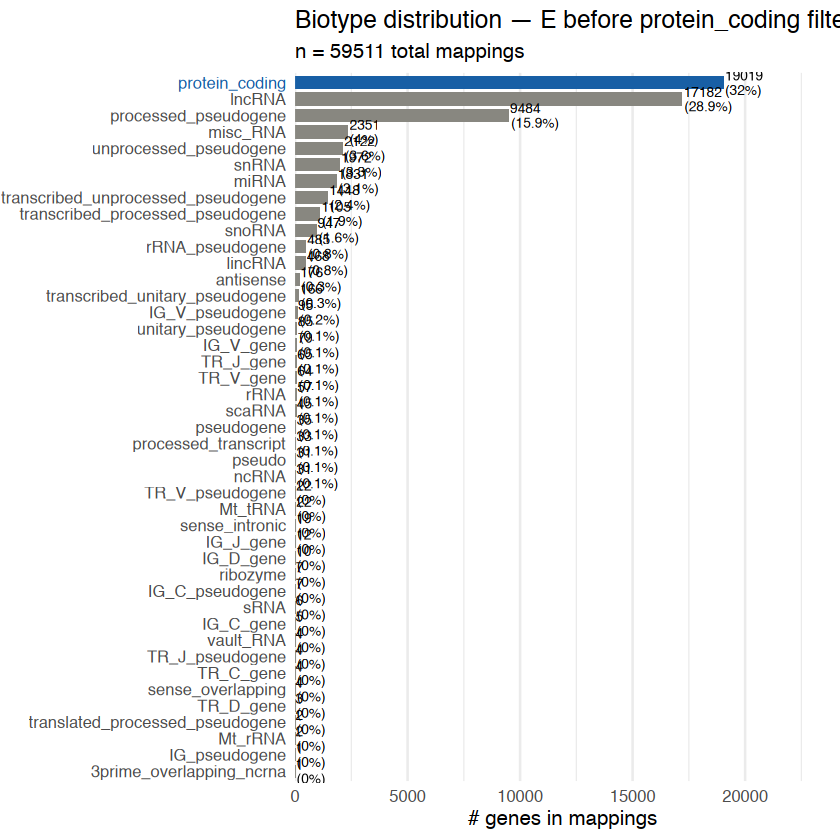

In [102]:
 # ── Filter E to protein_coding genes only ──────────────────
protein_coding_ensembl <- biotype_combined %>%
  filter(gene_biotype == "protein_coding") %>%
  pull(ensembl_gene_id)

E_filtered <- E_resolved[rownames(E_resolved) %in% protein_coding_ensembl,
  ,
  drop = FALSE
]

sprintf(
  "E before biotype filter: %d genes",
  nrow(E_resolved)
)

sprintf(
  "E after  biotype filter: %d genes",
  nrow(E_filtered)
)

plot_mapping_distribution(
  biotype_combined %>%
    filter(ensembl_gene_id %in% rownames(E_resolved)),
  category_col = "gene_biotype",
  highlight    = "protein_coding",
  heading      = "Biotype distribution — E before protein_coding filter")



---
## 5 · Preprocessing E and N for activities

The craTEs predefined preprocessing bundles several steps:
1. keeps only genes present in both E and N matrix

2. filter genes with less than 10 counts (low TE association)

3. remove TE-families that appear less than 150 times and stores in $lost_cols (low-predictor)

4. TPM normalisation to balance: seq-depth, rescaling, promotor-length

5. Add pseudocounts 

6. log2 transformation 

7. Row and Col Center expression matrix

#### ── Gene ID overlap before preprocessing ──

After duplicate resolution and biotype filtering, this diagnostic quantifies how well the reference N matrix covers the experiment-specific E matrix before preprocessing.

E genes: 19019
N genes: 19839
amount of genes we keep in E: 18268 (96.05% of E)
amount of genes we keep in N: 18268 (92.08% of N)
Common genes: 18268 (88.72% of union)
Only in E: 751 (3.95% of E, 3.65% of union)
Only in N: 1571 (7.92% of N, 7.63% of union)


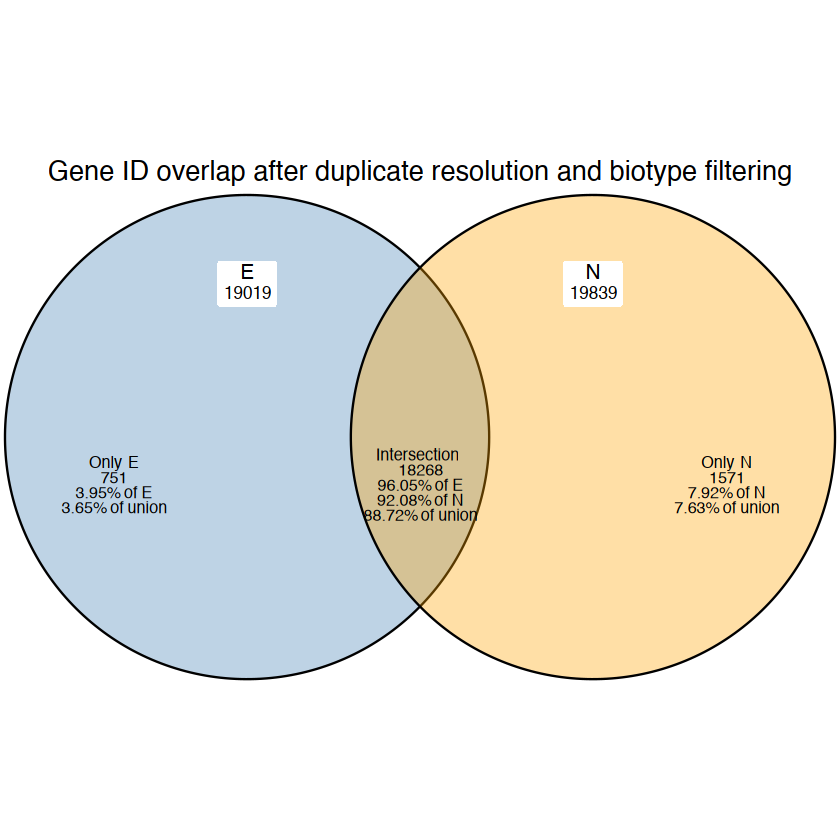

In [103]:
display_intersect(
  unique(rownames(E_filtered)),
  rownames(N),
  name_E = "E",
  name_N = "N",
  title = "Gene ID overlap after duplicate resolution and biotype filtering",
  plot = TRUE)

#### ── Filter low-predictor TE families ──

The TE-subfamily threshold diagnostic uses `threshold = 150` to show which columns preprocessing will discard later. TE subfamilies that are rarely inserted close to genes are assumed to provide weak predictors and are therefore filtered out in the next step.


p_npm threshold: 150
237 / 1076 subfamilies (22.0%) are discarded
839 / 1076 subfamilies (78.0%) are retained

Subfamilies below threshold (filtered):
  [1] "CR1-11_Crp"    "CR1-12_AMi"    "CR1-13_AMi"    "CR1-8_Crp"    
  [5] "CR1-L3B_Croc"  "Charlie11"     "Charlie12"     "Chompy-6_Croc"
  [9] "Chompy-7_Croc" "Eulor1"        "Eulor10"       "Eulor11"      
 [13] "Eulor12"       "Eulor2A"       "Eulor2B"       "Eulor2C"      
 [17] "Eulor3"        "Eulor5A"       "Eulor5B"       "Eulor6A"      
 [21] "Eulor6B"       "Eulor6C"       "Eulor6D"       "Eulor6E"      
 [25] "Eulor7"        "Eulor8"        "Eulor9A"       "Eulor9B"      
 [29] "Eulor9C"       "HERV-Fc1-int"  "HERV-Fc1_LTR1" "HERV-Fc1_LTR2"
 [33] "HERV-Fc1_LTR3" "HERV-Fc2-int"  "HERV-Fc2_LTR"  "HERV15-int"   
 [37] "HERV1_I-int"   "HERV1_LTRa"    "HERV1_LTRb"    "HERV1_LTRc"   
 [41] "HERV1_LTRd"    "HERV1_LTRe"    "HERV30-int"    "HERV9N-int"   
 [45] "HERVE_a-int"   "HERVFH19-int"  "HERVH48-int"   "HERVI-int"    
 [49] "H

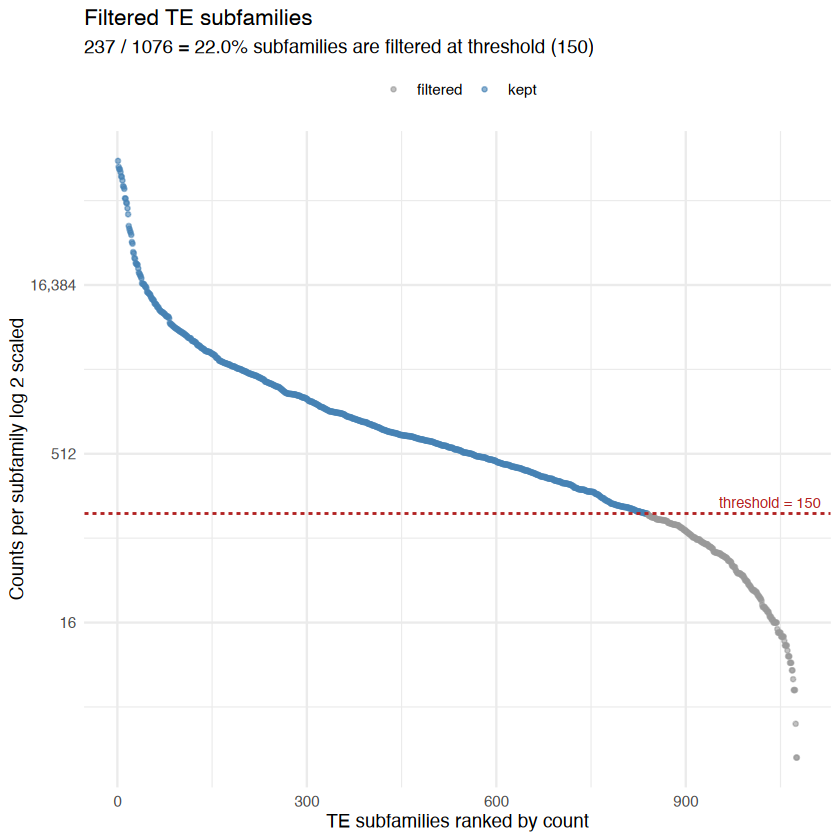

In [104]:
# which TE families would be discarded in preprocessing:
check_npm_threshold(N, threshold = 150)

#### ── Preprocessing ──

**Preprocessing settings.**  
`preprocess_E_N_for_activities()` is always sourced from `local_craTEs_extension/preprocess_E_N_for_activities_hg38.R`. The notebook uses the active `reference_genome`/`org`, and exon-length caches stay under `data/<reference_genome>/temp`.

In [105]:
# Local preprocessing for the selected reference genome.
source("local_craTEs_extension/preprocess_E_N_for_activities_hg38.R")

preprocess_exons_dir <- file.path("data", reference_genome, "temp")
res <- preprocess_E_N_for_activities(
  count_table = E_filtered,
  N = N,
  log_tpm_plot_path = file.path(log_dir, "log_tpm.pdf"),
  org = org,
  exons_dir = preprocess_exons_dir,
  hg38_source = "EnsDb.Hsapiens.v86")

E_centered <- res$E_centered
N_filtered  <- res$N

#### ── Verify Preprocessing ──

E genes: 14690
N genes: 14690
amount of genes we keep in E: 14690 (100.00% of E)
amount of genes we keep in N: 14690 (100.00% of N)
Common genes: 14690 (100.00% of union)
Only in E: 0 (0.00% of E, 0.00% of union)
Only in N: 0 (0.00% of N, 0.00% of union)


$duplicate_groups
[1] 0

$affected_rows
[1] 0

$redundant_rows
[1] 0

$table
NULL

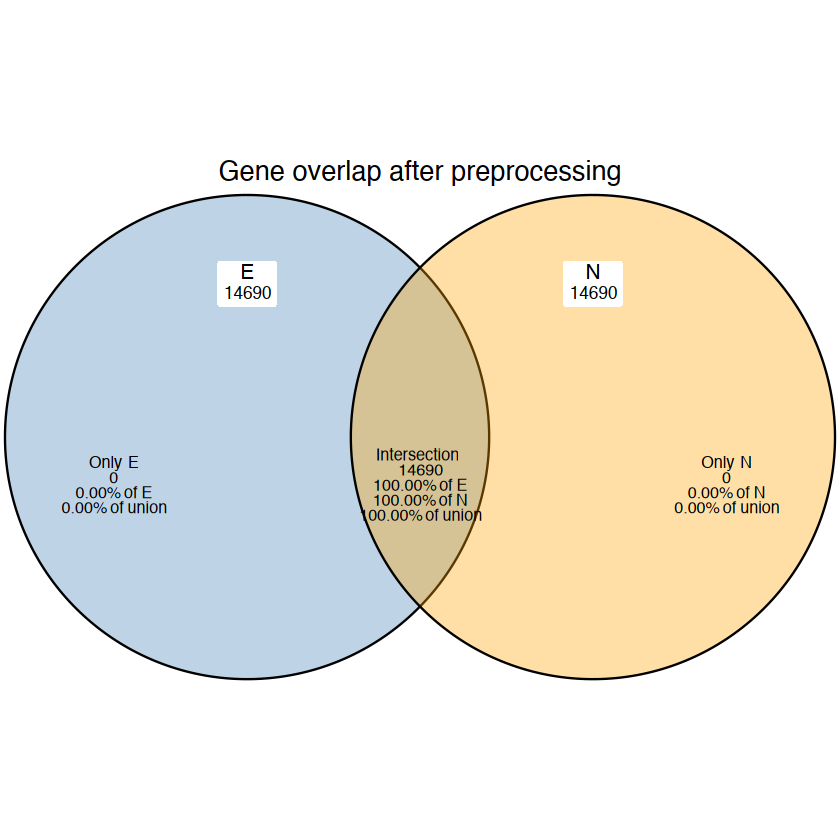

In [106]:
# Change to E_centered and N_filtered to inspect the matrices
# after preprocessing.
display_intersect(
  rownames(E_centered),
  rownames(N_filtered),
  name_E = "E",
  name_N = "N",
  title  = "Gene overlap after preprocessing")

duplicate_stats(
  rownames(E_centered),
  E_centered)

---

## 6 · Activity Estimation - penalised Linear Regression

### ──  Result Output Directory ──

We gather all the results for this experiment in a folder that is dependent on the matrix naming: 

In [107]:
# Location for exported activity results of this active E/N combination:
if (!exists("results_dir") || is.null(results_dir) || !nzchar(results_dir)) {
  results_dir <- derive_activity_results_dir(
    E_path = E_path,
    N_path = N_path,
    results_parent = file.path(getwd(), "results")
  )
}
figures_dir <- file.path(results_dir, "figures")
log_dir <- file.path(results_dir, "log")

dir.create(results_dir, showWarnings = FALSE, recursive = TRUE)
dir.create(figures_dir, showWarnings = FALSE, recursive = TRUE)
dir.create(log_dir, showWarnings = FALSE, recursive = TRUE)

options(crates.figures_dir = figures_dir, crates.log_dir = log_dir)
options(device = function(...) {grDevices::pdf(file = file.path(log_dir, "Rplots.pdf"), ...)})

results_dir_rel <- sub(
  paste0("^", normalizePath(getwd(), winslash = "/"), "/"),
  "",
  normalizePath(results_dir, winslash = "/")
)

print(results_dir_rel)


[1] "results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs"


### ──  6.1 - Activity Estimation  ──


This cell runs the solvment of the equation: 
> **E ≈ N x A**

`getActivities(E_centered, N_filtered)` and calcykates the TE activity matrix where the intercept row is removed. `A` contains only TE-subfamily activity coefficients.

| E | Sample 1 |   | N | TE_fam 1 | TE_fam 2 |   | A | A-score |
|---|----------|---|---|----------|----------|---|---|---------|
| Gene 1 | 10 | **=** | Gene 1 | 1 | 0 | **×** | TE_fam 1 | 3 |
| Gene 2 | 0 |   | Gene 2 | 2 | 1 |   | TE_fam 2 | 0 |

In [108]:
# ── CraTEs Activity ─────────────────────────────────────────
# local_craTEs_extension::getActivities override
act <- local({
  old_wd <- getwd()
  setwd(log_dir)
  on.exit(setwd(old_wd), add = TRUE)

  getActivities(E_centered, N_filtered)
})
A <- act$activities # TE activity matrix
A <- A[rownames(A) != "(Intercept)", , drop = FALSE]
colnames(A) <- colnames(E_centered)

[1] "Going parallel !"
Computing lambda max over  12  samples
Building the lambda gridRegressing activities of TFs for  12  samples
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
[1] "started new sample"
Finding the optimal lambda value across samples...
	... 1) Computing the per lambda MSE across samples
	... 2) retrieving the coefficients, crossval MSE, r_squared for the optimal lambda value


The boxplot is the first look at the elastic-net-like activity estimates, where many coefficients are expected to sit close to zero.

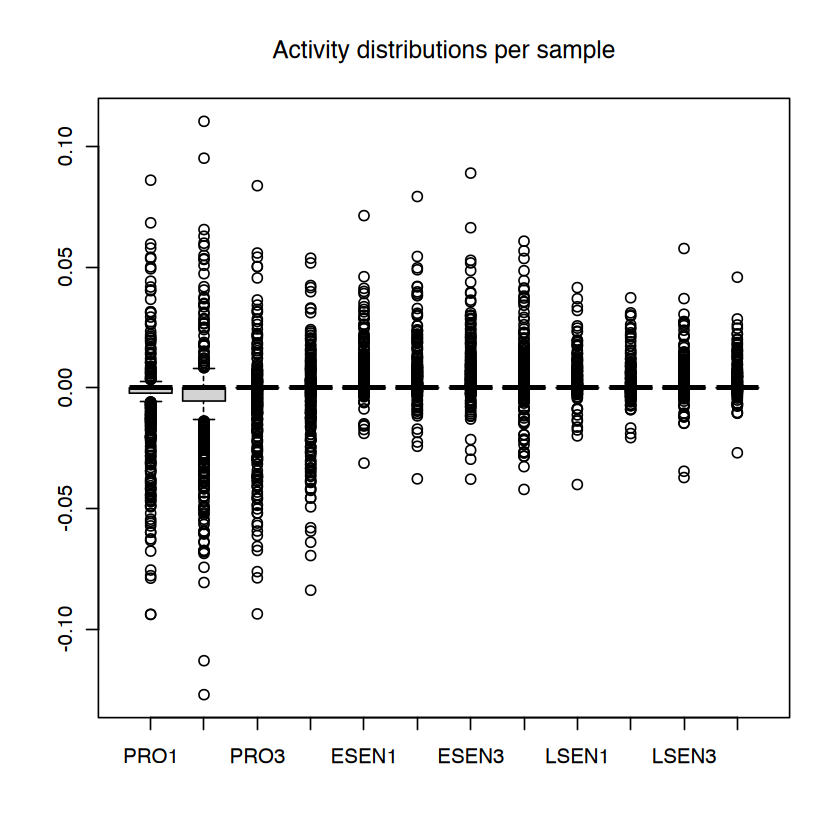

In [109]:
# Elastic net - penalised linear regression. (Activity coefficients close to 0) 
boxplot(as.matrix(A), main = "Activity distributions per sample")

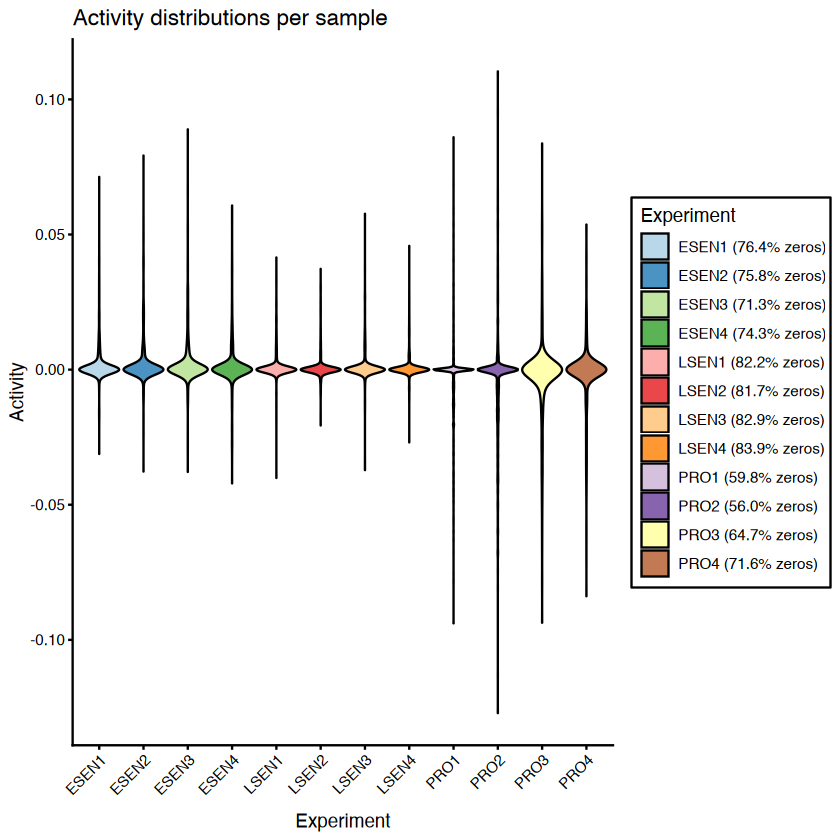

In [110]:
library(ggplot2)

sample_names <- colnames(A)
experiment <- sub("-rep[0-9]+$", "", sample_names)

ord <- order(experiment, sample_names)
sample_names <- sample_names[ord]
experiment <- experiment[ord]

A_long <- data.frame(
  sample = factor(rep(sample_names, each = nrow(A)), levels = sample_names),
  activity = as.vector(as.matrix(A[, sample_names, drop = FALSE])),
  experiment = rep(experiment, each = nrow(A))
)

zero_pct <- tapply(A_long$activity == 0, A_long$experiment, mean) * 100
experiment_labels <- paste0(names(zero_pct), " (", sprintf("%.1f%% zeros", zero_pct), ")")

x_labels <- experiment
x_labels[duplicated(experiment)] <- ""

ggplot(A_long, aes(x = sample, y = activity, fill = experiment)) +
  geom_violin(trim = TRUE, scale = "width", colour = "black", alpha = 0.8) +
  scale_fill_brewer(palette = "Paired", name = "Experiment", labels = experiment_labels) +
  scale_x_discrete(labels = x_labels) +
  theme_classic() +
  theme(
    axis.text.x = element_text(angle = 45, vjust = 1, hjust = 1),
    axis.title.x = element_text(margin = margin(t = 10)),
    legend.position = "right",
    legend.title = element_text(face = "bold"),
    legend.background = element_rect(fill = "white", colour = "black")
  ) +
  labs(
    title = "Activity distributions per sample",
    x = "Experiment",
    y = "Activity"
  )

In [111]:
# ranging plot files: move R's default plot file if the notebook kernel created it in the project root.
rplots_path <- file.path(log_dir, "Rplots.pdf")

if (file.exists("Rplots.pdf")) {
  if (file.exists(rplots_path)) {
    file.remove(rplots_path)
  }
  file.rename("Rplots.pdf", rplots_path)
}

**Output note.** The activity distribution plots are not meant to prove a biological result by itself; it checks whether the inferred activities have a plausible spread across samples before group-level comparisons.

In [112]:
# ── Save activity score matrix ─────────────────────────
activity_scores_tsv_path <- save_activity_score_matrix_tsv(
  activity_scores = A,
  output_path = file.path(results_dir, "activity_scores.tsv"),
  row_id_col = "te_subfamily",
  overwrite = TRUE)

activity_scores_tsv_rel <- sub(
  paste0("^", normalizePath(getwd(), winslash = "/"), "/"),
  "",
  normalizePath(activity_scores_tsv_path, winslash = "/"))

print(activity_scores_tsv_rel)

[1] "results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/activity_scores.tsv"


### ── 6.2 Model fit diagnostics ──

These diagnostics quantify how much variance in gene expression (`E`) is explained by the TE activity model (`N x A`) and how sparse the inferred activity matrix is.

The active TE-Seq dataset has three sample classes: `PRO` (proliferating), `ESEN` (early senescence), and `LSEN` (late senescence). `sample_conditions` is assigned from the sample-name prefixes and is used to summarise model fit by biological state.

The notebook builds the model-fit tables here, prints the summary, and saves the tables in the next cell to the same experiment-specific `results_dir` as `activity_scores.tsv`:

- `sample_activity_diagnostics.tsv`: one row per sample with condition, R², R²/R²max, activity sparsity, sample-specific `lambda_best`, and the selected global lambda when available.

- `activity_fit_summary.tsv`: one overall row and one row per condition with mean R², mean R²/R²max, and mean sparsity.

- `activity_lambda_diagnostics.tsv`: the global lambda grid, cross-sample mean CV MSE, CV MSE SD, and the global lambda selected for the activity coefficients.

In [113]:
colnames(A)

[1] "PRO1"  "PRO2"  "PRO3"  "PRO4"  "ESEN1" "ESEN2" "ESEN3" "ESEN4" "LSEN1"
[10] "LSEN2" "LSEN3" "LSEN4"

In [114]:
# ── Model fit diagnostics and export tables ───────────────────────
sample_conditions <- ifelse(grepl("^PRO", colnames(A)), "PRO",
                     ifelse(grepl("^ESEN", colnames(A)), "ESEN",
                     ifelse(grepl("^LSEN", colnames(A)), "LSEN", NA_character_)))

sample_conditions <- setNames(sample_conditions, colnames(A))

expected_samples <- c(paste0("PRO", 1:4), paste0("ESEN", 1:4), paste0("LSEN", 1:4))
if (!setequal(colnames(A), expected_samples)) {
  stop(
    sprintf(
      "A samples do not match the expected TE-Seq sample set. Missing: %s | Extra: %s",
      paste(setdiff(expected_samples, colnames(A)), collapse = ", "),
      paste(setdiff(colnames(A), expected_samples), collapse = ", ")
    ),
    call. = FALSE)}
if (any(is.na(sample_conditions))) {
  stop("Some samples could not be assigned to PRO, ESEN, or LSEN from their name prefix.", call. = FALSE)}

# Build diagnostics for printing and logging.
activity_fit_tables <- build_activity_fit_tables(
  act = act,
  A = A,
  sample_conditions = sample_conditions)

sample_activity_diagnostics <- activity_fit_tables$sample_activity_diagnostics
activity_fit_summary <- activity_fit_tables$activity_fit_summary
activity_lambda_diagnostics <- activity_fit_tables$activity_lambda_diagnostics
overall_fit <- activity_fit_summary[activity_fit_summary$scope == "overall", , drop = FALSE]

cat("
── Model fit ───────────────────────────────
")
cat(sprintf("Mean R²:              %.3f
", overall_fit$mean_r2))
cat(sprintf("Mean R²/R²_max:       %.3f  (expected: 0.6-0.9)
", overall_fit$mean_r2_ratio))
cat(sprintf("Sparsity of A:        %.2f%% zeros
", overall_fit$mean_sparsity_percent))

cat("
Condition means:
")
print(
  activity_fit_summary[activity_fit_summary$scope == "condition", c(
    "condition", "n_samples", "mean_r2", "mean_r2_ratio", "mean_sparsity_percent"
  )],
  row.names = FALSE)


── Model fit ───────────────────────────────
Mean R²:              0.094
Mean R²/R²_max:       0.678  (expected: 0.6-0.9)
Sparsity of A:        73.39% zeros

Condition means:
 condition n_samples    mean_r2 mean_r2_ratio mean_sparsity_percent
       PRO         4 0.12339870     0.7757489              63.02356
      ESEN         4 0.07336192     0.6205579              74.47644
      LSEN         4 0.08426866     0.6379700              82.65707


In [115]:
# ── Save model fit diagnostics ─────────────────────────
saved_model_fit_statistics <- rbind(
  write_result_object(
    input_dir = results_dir,
    name = "sample_activity_diagnostics",
    object = sample_activity_diagnostics,
    write_tsv = TRUE,
    write_rds = FALSE,
    overwrite = TRUE
  ),
  write_result_object(
    input_dir = results_dir,
    name = "activity_fit_summary",
    object = activity_fit_summary,
    write_tsv = TRUE,
    write_rds = FALSE,
    overwrite = TRUE
  )
)

if (!is.null(activity_lambda_diagnostics)) {
  saved_model_fit_statistics <- rbind(
    saved_model_fit_statistics,
    write_result_object(
      input_dir = results_dir,
      name = "activity_lambda_diagnostics",
      object = activity_lambda_diagnostics,
      write_tsv = TRUE,
      write_rds = FALSE,
      overwrite = TRUE
    )
  )
}

saved_model_fit_statistics


name,format,path
<chr>,<chr>,<chr>
sample_activity_diagnostics,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/sample_activity_diagnostics.tsv
activity_fit_summary,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/activity_fit_summary.tsv
activity_lambda_diagnostics,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/activity_lambda_diagnostics.tsv


**Interpretation note.** Moderate model fit is expected in this high-dimensional regression setting, because broad gene-expression patterns are inferred from many TE-derived predictors. The diagnostics are therefore used to check relative model quality and sparsity, not to claim exact expression prediction. If fit is unusually weak or activity sparsity is extreme, downstream senescence-contrast interpretations should be treated cautiously.


---

## 7 · Differential Activity


The role of an Transposable Element as cis-rgulatory enhancer may change over cell condtion. A filobplast can actviate gene expression in poliferating cells but downregulate them in early senescence.  
 
The TE-Seq comparisons are defined between two cell states. The contrast direction is always `first condition - second condition`, so positive deltas and positive significance coefficients mean higher inferred TE activity in the first condition.

The three comparisons are 
`ESEN_vs_PRO` (early senescence - proliferating)
`LSEN_vs_PRO` (late senescence - proliferating)
`LSEN_vs_ESEN` (late senescence - early senescence)

In [116]:
# ── Define TE-Seq sample groups and contrasts ──────────
expected_samples <- c(paste0("PRO", 1:4), paste0("ESEN", 1:4), paste0("LSEN", 1:4))
if (!setequal(colnames(A), expected_samples) || !setequal(colnames(E_centered), expected_samples)) {
  stop("A and E_centered must contain exactly PRO1-4, ESEN1-4, and LSEN1-4 for this TE-Seq analysis.", call. = FALSE)}

samples_PRO  <- paste0("PRO", 1:4)
samples_ESEN <- paste0("ESEN", 1:4)
samples_LSEN <- paste0("LSEN", 1:4)

condition_groups <- list(PRO = samples_PRO, ESEN = samples_ESEN, LSEN = samples_LSEN)
condition_cols <- c(PRO = "grey35", ESEN = "steelblue", LSEN = "tomato")

senescence_contrasts <- list(
  ESEN_vs_PRO  = list(treatment = samples_ESEN, control = samples_PRO,  label = "ESEN vs PRO"),
  LSEN_vs_PRO  = list(treatment = samples_LSEN, control = samples_PRO,  label = "LSEN vs PRO"),
  LSEN_vs_ESEN = list(treatment = samples_LSEN, control = samples_ESEN, label = "LSEN vs ESEN"))

print(data.frame(
  condition = c("PRO", "ESEN", "LSEN"),
  samples = c(
    paste(samples_PRO, collapse = ", "),
    paste(samples_ESEN, collapse = ", "),
    paste(samples_LSEN, collapse = ", ")
  ),
  stringsAsFactors = FALSE))


  condition                    samples
1       PRO     PRO1, PRO2, PRO3, PRO4
2      ESEN ESEN1, ESEN2, ESEN3, ESEN4
3      LSEN LSEN1, LSEN2, LSEN3, LSEN4


### ── 7.1 - TE activity ranking and condition scores ──

Dependent on the analysed interest TE-subfamilies can be ranked differently. 
Here is an overview of preimplemented ranking possibilities to inspect these cases furthermore downstream. 

| Ranking / class | Score or criterion | What it prioritises |
|---|---|---|
| `sum_step_abs_delta` default | $\lvert ESEN - POL \rvert + \lvert LSEN - ESEN \rvert$ | Overall dynamics; uses both adjacent gaps equally. |
| `max_step_abs_delta` | $\max(\lvert ESEN - POL \rvert, \lvert LSEN - ESEN \rvert)$ | Strongest adjacent gap; `ESEN - POL` only dominates if it is the larger step. |
| `max_sum_abs_activity_score` | $\max_c \sum_{i \in c} \lvert score_i \rvert$ | Highest condition-wise total absolute activity; prioritises strongly active TE subfamilies independent of direction. |
| `abs_delta_ESEN_vs_POL` | $\lvert ESEN - POL \rvert$ | Early senescence gap only. |
| `abs_delta_LSEN_vs_ESEN` | $\lvert LSEN - ESEN \rvert$ | Late senescence gap only. |
| `POL_LSEN` / `abs_delta_LSEN_vs_POL` | $\lvert LSEN - POL \rvert$ | Start-to-end gap only; ESEN is ignored. |
| `net_abs_delta` | same as `abs_delta_LSEN_vs_POL` | Backward-compatible name for the `POL_LSEN` gap. |
| `increasing` | $d_{EP} \geq threshold$ and $d_{LE} \geq threshold$ | Stepwise activity gain across senescence. |
| `decreasing` | $d_{EP} \leq -threshold$ and $d_{LE} \leq -threshold$ | Stepwise activity loss across senescence. |
| `pol_peak` | $d_{EP} \leq -threshold$ and $d_{LP} \leq -threshold$ | Highest activity in POL. |
| `esen_peak` | $d_{EP} \geq threshold$ and $d_{LE} \leq -threshold$ | Highest activity in ESEN. |
| `lsen_peak` | $d_{LP} \geq threshold$ and $d_{LE} \geq threshold$ | Highest activity in LSEN. |
| `pol_drop` | $d_{EP} \geq threshold$ and $d_{LP} \geq threshold$ | Lowest activity in POL. |
| `esen_drop` | $d_{EP} \leq -threshold$ and $d_{LE} \geq threshold$ | Lowest activity in ESEN. |
| `lsen_drop` | $d_{LP} \leq -threshold$ and $d_{LE} \leq -threshold$ | Lowest activity in LSEN. |
| `flat_or_noisy` | No clean threshold-passing pattern | No robust trajectory class. |

Definitions:

$d_{EP} = ESEN - POL$  
$d_{LE} = LSEN - ESEN$  
$d_{LP} = LSEN - POL$

The ranking score only selects and orders TE subfamilies. The plots below still show the original inferred activity scores from `A`, so a top-ranked TE is a TE whose mean activity changes strongly for the chosen metric, not necessarily the TE with the largest absolute activity in every sample.

The pairwise `plot_delta_activity()` calls are silent here; they create `delta_activity_ESEN_vs_PRO`, `delta_activity_LSEN_vs_PRO`, and `delta_activity_LSEN_vs_ESEN` for downstream summaries without printing separate plots.

In [117]:
# -- Silent pairwise delta tables and ranking settings -----------
delta_top_k <- 10L
delta_top_k_metric <- "sum_step_abs_delta"
# For a one-gap PRO_LSEN ranking, use:
# delta_top_k_metric <- "PRO_LSEN"

delta_activity_ranking_metric_choices <- c(
  "sum_step_abs_delta",
  "max_step_abs_delta",
  "max_sum_abs_activity_score",
  "abs_delta_ESEN_vs_PRO",
  "abs_delta_LSEN_vs_ESEN",
  "abs_delta_LSEN_vs_PRO",
  "net_abs_delta",
  "mean_activity_range",
  "monotonic_step_abs_delta",
  "PRO_ESEN",
  "ESEN_LSEN",
  "PRO_LSEN")

delta_activity_ranking_metric_labels <- c(
  sum_step_abs_delta = "sum of adjacent mean activity changes",
  max_step_abs_delta = "maximum adjacent mean activity change",
  max_sum_abs_activity_score = "max condition sum of absolute activity scores",
  abs_delta_ESEN_vs_PRO = "absolute ESEN-vs-PRO mean activity gap",
  abs_delta_LSEN_vs_ESEN = "absolute LSEN-vs-ESEN mean activity gap",
  abs_delta_LSEN_vs_PRO = "absolute LSEN-vs-PRO mean activity gap",
  net_abs_delta = "net PRO-to-LSEN mean activity change",
  mean_activity_range = "condition mean activity range",
  monotonic_step_abs_delta = "monotonic adjacent mean activity change",
  PRO_ESEN = "absolute PRO-to-ESEN mean activity gap",
  ESEN_LSEN = "absolute ESEN-to-LSEN mean activity gap",
  PRO_LSEN = "absolute PRO-to-LSEN mean activity gap")

delta_top_k_metric <- match.arg(delta_top_k_metric, delta_activity_ranking_metric_choices)

delta_activity_ESEN_vs_PRO <- plot_delta_activity(
  activity_scores = A,
  treatment_samples = samples_ESEN,
  control_samples = samples_PRO,
  condition_label = "ESEN vs PRO",
  top_k = delta_top_k,
  te_subfamilies = NULL,
  title = "ESEN - PRO delta activity",
  treatment_label = "ESEN",
  control_label = "PRO",
  plot = FALSE,
  print_table = FALSE)

delta_activity_LSEN_vs_PRO <- plot_delta_activity(
  activity_scores = A,
  treatment_samples = samples_LSEN,
  control_samples = samples_PRO,
  condition_label = "LSEN vs PRO",
  top_k = delta_top_k,
  te_subfamilies = NULL,
  title = "LSEN - PRO delta activity",
  treatment_label = "LSEN",
  control_label = "PRO",
  plot = FALSE,
  print_table = FALSE)

delta_activity_LSEN_vs_ESEN <- plot_delta_activity(
  activity_scores = A,
  treatment_samples = samples_LSEN,
  control_samples = samples_ESEN,
  condition_label = "LSEN vs ESEN",
  top_k = delta_top_k,
  te_subfamilies = NULL,
  title = "LSEN - ESEN delta activity",
  treatment_label = "LSEN",
  control_label = "ESEN",
  plot = FALSE,
  print_table = FALSE)


In [118]:
# -- Shared TE activity ranking table -------------------------------
if (!exists("delta_top_k", inherits = TRUE)) {
  delta_top_k <- 10L
}
if (!exists("delta_top_k_metric", inherits = TRUE)) {
  delta_top_k_metric <- "sum_step_abs_delta"
}
if (!exists("delta_activity_ranking_metric_choices", inherits = TRUE)) {
  delta_activity_ranking_metric_choices <- c(
    "sum_step_abs_delta",
    "max_step_abs_delta",
    "max_sum_abs_activity_score",
    "abs_delta_ESEN_vs_PRO",
    "abs_delta_LSEN_vs_ESEN",
    "abs_delta_LSEN_vs_PRO",
    "net_abs_delta",
    "mean_activity_range",
    "monotonic_step_abs_delta",
    "PRO_ESEN",
    "ESEN_LSEN",
    "PRO_LSEN")
}
if (!exists("delta_activity_ranking_metric_labels", inherits = TRUE)) {
  delta_activity_ranking_metric_labels <- c(
    sum_step_abs_delta = "sum of adjacent mean activity changes",
    max_step_abs_delta = "maximum adjacent mean activity change",
    max_sum_abs_activity_score = "max condition sum of absolute activity scores",
    abs_delta_ESEN_vs_PRO = "absolute ESEN-vs-PRO mean activity gap",
    abs_delta_LSEN_vs_ESEN = "absolute LSEN-vs-ESEN mean activity gap",
    abs_delta_LSEN_vs_PRO = "absolute LSEN-vs-PRO mean activity gap",
    net_abs_delta = "net PRO-to-LSEN mean activity change",
    mean_activity_range = "condition mean activity range",
    monotonic_step_abs_delta = "monotonic adjacent mean activity change",
    PRO_ESEN = "absolute PRO-to-ESEN mean activity gap",
    ESEN_LSEN = "absolute ESEN-to-LSEN mean activity gap",
    PRO_LSEN = "absolute PRO-to-LSEN mean activity gap")
}

delta_top_k_metric <- match.arg(delta_top_k_metric, delta_activity_ranking_metric_choices)
delta_activity_ranking_label <- unname(delta_activity_ranking_metric_labels[delta_top_k_metric])
if (length(delta_activity_ranking_label) == 0L || is.na(delta_activity_ranking_label)) {
  delta_activity_ranking_label <- delta_top_k_metric
}

delta_activity_te_selection <- select_top_te_subfamilies_by_activity_change(
  activity_scores = A,
  condition_groups = condition_groups,
  condition_order = c("PRO", "ESEN", "LSEN"),
  top_k = delta_top_k,
  ranking_metric = delta_top_k_metric,
  te_subfamilies = NULL)

if (is.unsorted(-delta_activity_te_selection$ranking_score, strictly = FALSE)) {
  stop("delta_activity_te_selection is not sorted by descending ranking_score.", call. = FALSE)
}

delta_activity_te_selection$rank <- seq_len(nrow(delta_activity_te_selection))
ranked_delta_table <- data.frame(
  te_subfamily = delta_activity_te_selection$te_subfamily,
  delta_activity = delta_activity_te_selection$ranking_score,
  stringsAsFactors = FALSE)

ranking_display_cols <- intersect(
  c(
    "rank",
    "te_subfamily",
    "ranking_score",
    "mean_PRO",
    "mean_ESEN",
    "mean_LSEN",
    "sum_abs_activity_PRO",
    "sum_abs_activity_ESEN",
    "sum_abs_activity_LSEN",
    "delta_ESEN_vs_PRO",
    "delta_LSEN_vs_ESEN",
    "delta_LSEN_vs_PRO",
    "abs_delta_ESEN_vs_PRO",
    "abs_delta_LSEN_vs_ESEN",
    "abs_delta_LSEN_vs_PRO"
  ),
  colnames(delta_activity_te_selection)
)
ranking_display <- delta_activity_te_selection[, ranking_display_cols, drop = FALSE]
numeric_cols <- vapply(ranking_display, is.numeric, logical(1))
ranking_display[numeric_cols] <- lapply(ranking_display[numeric_cols], round, digits = 4)

# ranking_display is kept available for manual inspection.


### ── 7.1b - TE subfamilies with the strongest absolute cis-regulatory activity signal ──

#### Ranking score

$$
R_t = \max_{c \in \{PRO, ESEN, LSEN\}} \sum_{i \in c} \left| A_{t,i} \right|
$$

$A_{t,i}$ is the inferred activity score of TE subfamily $t$ in replicate $i$.

In [119]:
# -- Ranking: strongest absolute activity signal -------------------------------
if (!exists("delta_top_k", inherits = TRUE)) {
  delta_top_k <- 10L
}

max_sum_abs_activity_condition_order <- c("PRO", "ESEN", "LSEN")
max_sum_abs_activity_metric <- "max_sum_abs_activity_score"
max_sum_abs_activity_ranking_label <- "max condition sum of absolute activity scores"

if (exists("delta_activity_ranking_metric_labels", inherits = TRUE) &&
    max_sum_abs_activity_metric %in% names(delta_activity_ranking_metric_labels)) {
  max_sum_abs_activity_ranking_label <- unname(delta_activity_ranking_metric_labels[max_sum_abs_activity_metric])
}

max_sum_abs_activity_te_selection <- select_top_te_subfamilies_by_activity_change(
  activity_scores = A,
  condition_groups = condition_groups,
  condition_order = max_sum_abs_activity_condition_order,
  top_k = delta_top_k,
  ranking_metric = max_sum_abs_activity_metric,
  te_subfamilies = NULL)

if (is.unsorted(-max_sum_abs_activity_te_selection$ranking_score, strictly = FALSE)) {
  stop("max_sum_abs_activity_te_selection is not sorted by descending ranking_score.", call. = FALSE)
}

max_sum_abs_activity_te_selection$rank <- seq_len(nrow(max_sum_abs_activity_te_selection))
max_sum_abs_activity_ranked_table <- data.frame(
  te_subfamily = max_sum_abs_activity_te_selection$te_subfamily,
  delta_activity = max_sum_abs_activity_te_selection$ranking_score,
  stringsAsFactors = FALSE)

max_sum_abs_activity_ranking_display_cols <- intersect(
  c(
    "rank",
    "te_subfamily",
    "ranking_score",
    paste0("mean_activity_", max_sum_abs_activity_condition_order),
    paste0("sum_abs_activity_", max_sum_abs_activity_condition_order)
  ),
  colnames(max_sum_abs_activity_te_selection)
)
max_sum_abs_activity_ranking_display <- max_sum_abs_activity_te_selection[, max_sum_abs_activity_ranking_display_cols, drop = FALSE]
numeric_cols <- vapply(max_sum_abs_activity_ranking_display, is.numeric, logical(1))
max_sum_abs_activity_ranking_display[numeric_cols] <- lapply(max_sum_abs_activity_ranking_display[numeric_cols], round, digits = 4)

max_sum_abs_activity_ranking_display


rank,te_subfamily,ranking_score,sum_abs_activity_PRO,sum_abs_activity_ESEN,sum_abs_activity_LSEN
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,HERV4_I-int,0.3986,0.3986,0.2750,0.0017
2,LTR13,0.3216,0.3216,0.1338,0.1007
3,MamGypsy2-LTR,0.2895,0.2895,0.0023,0.1760
4,MER52A,0.2640,0.2640,0.0865,0.0715
5,MamRep488,0.2474,0.2474,0.1667,0.0000
6,LTR88a,0.2438,0.2438,0.0882,0.0390
7,MER110,0.2327,0.2327,0.0556,0.0333
8,MamGypLTR1a,0.2326,0.2326,0.1098,0.0190
9,MER61B,0.2296,0.2296,0.1183,0.0000


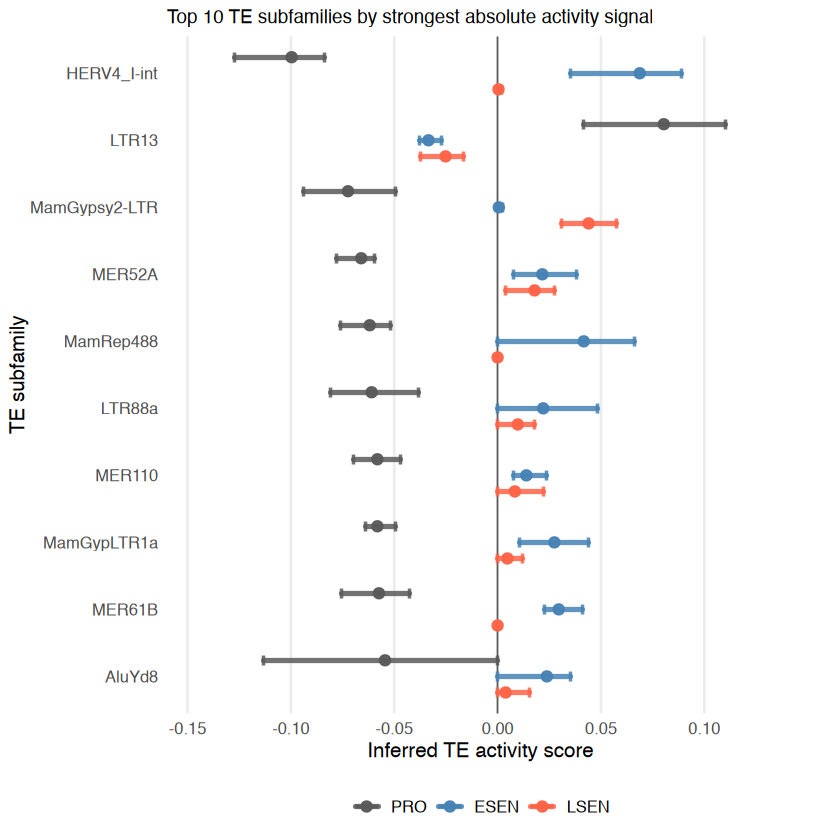

In [120]:
# -- Plot: reuse the condition-range renderer for the selected ranking ----------
required <- c(
  "max_sum_abs_activity_te_selection",
  "max_sum_abs_activity_ranked_table",
  "max_sum_abs_activity_condition_order",
  "max_sum_abs_activity_ranking_label"
)
missing <- required[!vapply(required, exists, logical(1), inherits = TRUE)]
if (length(missing) > 0L) {
  stop(sprintf("Run the max-sum absolute activity ranking cell first. Missing: %s", paste(missing, collapse = ", ")), call. = FALSE)
}

delta_plot_max_sum_abs_activity <- plot_delta_activity_condition_ranges(
  activity_scores = A,
  delta_table = max_sum_abs_activity_ranked_table,
  condition_groups = condition_groups,
  condition_order = max_sum_abs_activity_condition_order,
  condition_cols = condition_cols,
  condition_label = max_sum_abs_activity_ranking_label,
  title = sprintf("Top %s TE subfamilies by strongest absolute activity signal", nrow(max_sum_abs_activity_te_selection)),
  x_label = "Inferred TE activity score",
  selection_label = max_sum_abs_activity_ranking_label,
  show_subtitle = FALSE)

delta_plot_max_sum_abs_activity


### ── 7.2 - Top TE subfamilies that have the biggest change in their cis-regulatory activity ──

This plot reuses `delta_activity_te_selection` and `ranked_delta_table` from Section 7.1. TE subfamilies stay in the selected ranking order from `delta_top_k_metric`; the x-axis shows the original inferred activity scores per condition. Brackets mark replicate min-to-max ranges and dots mark condition means.


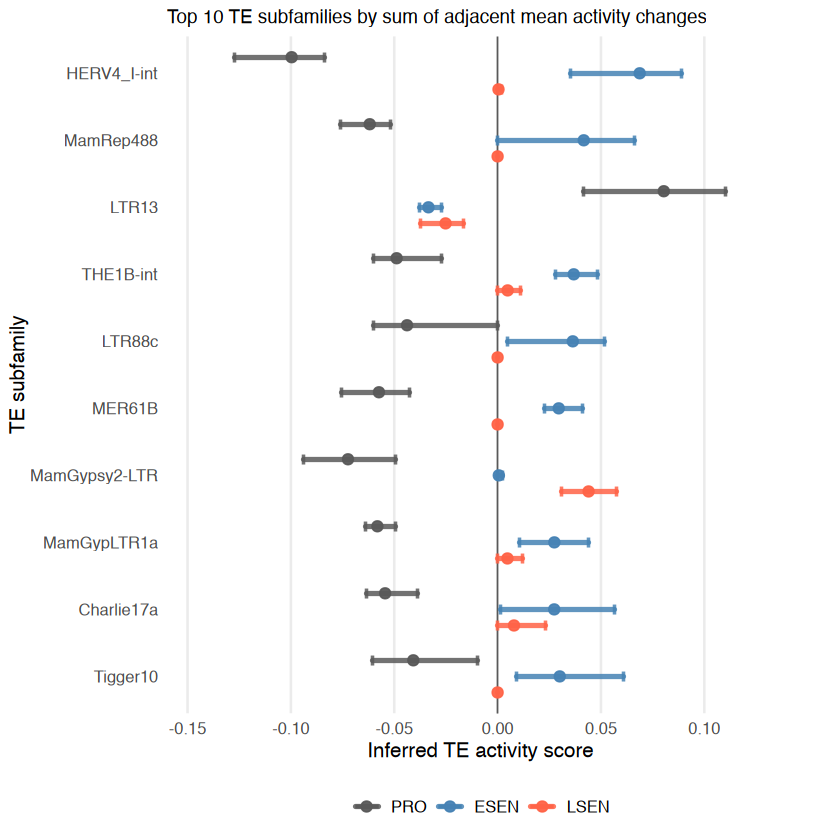

In [121]:
# -- Ranked condition-range plot for activity-score changes --------
if (!exists("delta_activity_te_selection", inherits = TRUE) ||
    !exists("ranked_delta_table", inherits = TRUE) ||
    !exists("delta_activity_ranking_label", inherits = TRUE)) {
  stop("Run the Section 7.1 ranking cells before plotting ranked activity scores.", call. = FALSE)
}

delta_plot_ranked_condition_ranges <- plot_delta_activity_condition_ranges(
  activity_scores = A,
  delta_table = ranked_delta_table,
  condition_groups = condition_groups,
  condition_order = c("PRO", "ESEN", "LSEN"),
  condition_cols = condition_cols,
  condition_label = delta_activity_ranking_label,
  title = sprintf("Top %s TE subfamilies by %s", nrow(delta_activity_te_selection), delta_activity_ranking_label),
  x_label = "Inferred TE activity score",
  selection_label = delta_activity_ranking_label,
  show_subtitle = FALSE)

delta_plot_ranked_condition_ranges


### ── 7.3 - Activity scores across conditions ──

Here we plot activty scores across samples for specific TE subfamilies. if not provided, the top six ranked TE subfamilies from the Section 7.1 are plotted. 

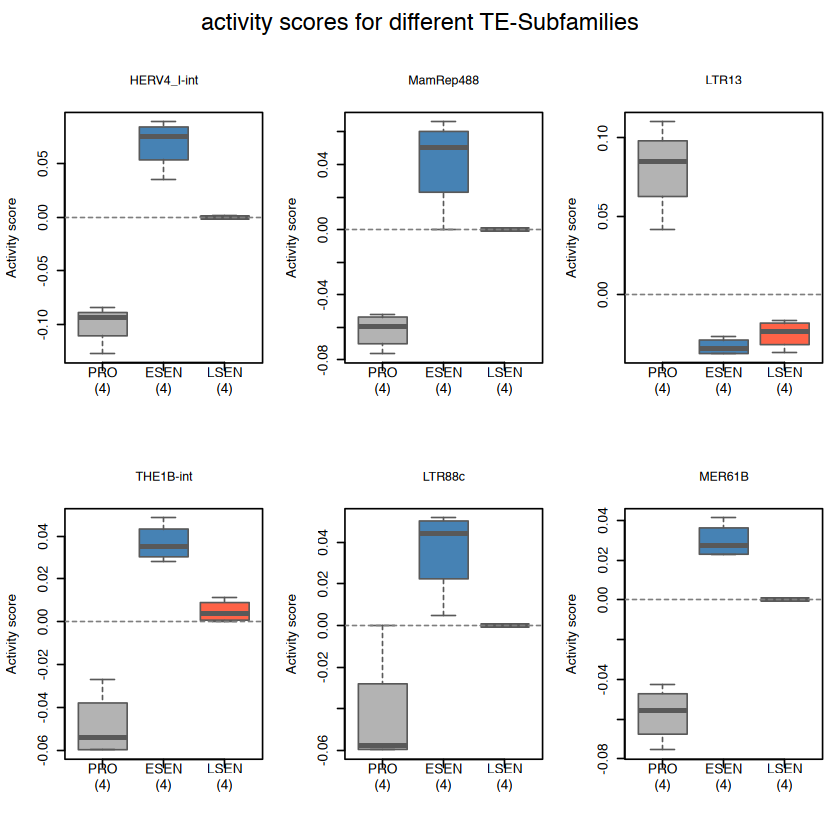

In [122]:
# -- Activity score plots for ranked or selected TE subfamilies ----
activity_condition_cols <- c(PRO = "grey70", ESEN = "steelblue", LSEN = "tomato")
activity_point_cols <- grDevices::adjustcolor(activity_condition_cols, alpha.f = 0.75)
top_n_activity <- 6L

missing_samples <- setdiff(unlist(condition_groups, use.names = FALSE), colnames(A))
if (length(missing_samples) > 0L) {
  stop(sprintf("Samples missing from A colnames: %s", paste(missing_samples, collapse = ", ")), call. = FALSE)
}

requested_te_subfamilies <- character(0)
if (exists("TE_subfamilies", inherits = TRUE) && !is.null(TE_subfamilies)) {
  requested_te_subfamilies <- unique(as.character(unlist(TE_subfamilies, use.names = FALSE)))
  requested_te_subfamilies <- requested_te_subfamilies[nzchar(requested_te_subfamilies)]
}

if (length(requested_te_subfamilies) > 0L) {
  missing_tes <- setdiff(requested_te_subfamilies, rownames(A))
  if (length(missing_tes) > 0L) {
    warning(
      sprintf("Requested TE subfamilies not found in A rownames: %s", paste(missing_tes, collapse = ", ")),
      call. = FALSE)
  }
  tes_to_plot <- requested_te_subfamilies[requested_te_subfamilies %in% rownames(A)]
} else {
  if (!exists("delta_activity_te_selection", inherits = TRUE)) {
    stop("Run the Section 7.1 ranking cell before plotting activity scores.", call. = FALSE)
  }
  ranked_activity <- delta_activity_te_selection[
    is.finite(delta_activity_te_selection$ranking_score),
    ,
    drop = FALSE]
  ranked_activity <- ranked_activity[order(-ranked_activity$ranking_score, ranked_activity$te_subfamily), , drop = FALSE]
  tes_to_plot <- head(ranked_activity$te_subfamily, top_n_activity)
}

if (length(tes_to_plot) == 0L) {
  stop("No TE subfamilies were available for activity-score plotting.", call. = FALSE)
}

n_cols <- min(3L, length(tes_to_plot))
old_par <- par(no.readonly = TRUE)
par(
  mfrow = c(ceiling(length(tes_to_plot) / n_cols), n_cols),
  oma = c(0, 0, 3, 0),
  mar = c(5, 4, 4, 1) + 0.1
)

for (te in tes_to_plot) {
  plot_data <- lapply(condition_groups, function(samples) as.numeric(A[te, samples]))
  boxplot(
    plot_data,
    names = sprintf("%s\n(%d)", names(condition_groups), lengths(condition_groups)),
    main = te,
    ylab = "Activity score",
    col = activity_condition_cols[names(condition_groups)],
    border = "grey35",
    cex.main = 0.9
  )
  stripchart(
    plot_data,
    vertical = TRUE,
    method = "jitter",
    jitter = 0.08,
    pch = 16,
    cex = 0.85,
    col = activity_point_cols[names(condition_groups)],
    add = TRUE
  )
  abline(h = 0, lty = 2, col = "grey50")
}

mtext(
  "activity scores for different TE-Subfamilies",
  outer = TRUE,
  cex = 1.15,
  font = 2,
  line = 1
)
par(old_par)


**Output note.** These panels show condition-level activity distributions and individual replicate activity scores for the ranked or manually selected TE subfamilies.


### ── 7.4 - Quality control: activity correlations across biological replicates ──

Activity correlations are summarised at condition level using `activity_condition_correlations()` from `scripts/craTEs_own_function.R`. Within-condition values average all replicate-pair correlations for one senescence state; the sample-agreement lines show, for each sample, its mean correlation to the other replicates from the same condition. Between-condition values average all cross-condition sample-pair correlations for a pair of states.


In [123]:
# -- Compact activity correlation summary -------------------------
activity_correlation_qc <- activity_condition_correlations(
  activity_scores = A,
  sample_groups = condition_groups,
  print_table = TRUE)

activity_correlation_summary <- activity_correlation_qc$summary
activity_sample_correlation_summary <- activity_correlation_qc$sample_summary
activity_pair_correlation_table <- activity_correlation_qc$pairs



── Activity correlation summary ──────────────────
Within condition means:
ESEN:          0.575  (6 pairs)
LSEN:          0.702  (6 pairs)
PRO:           0.791  (6 pairs)

Within-condition sample agreement:
PRO: PRO1=0.818, PRO2=0.789, PRO3=0.841, PRO4=0.716
ESEN: ESEN1=0.653, ESEN2=0.689, ESEN3=0.669, ESEN4=0.290
LSEN: LSEN1=0.696, LSEN2=0.615, LSEN3=0.752, LSEN4=0.745

Lowest within-condition sample agreement:
ESEN:          ESEN4 0.290
LSEN:          LSEN2 0.615
PRO:           PRO4 0.716

Between condition means:
ESEN vs LSEN:  0.149  (16 pairs)
PRO vs ESEN:   -0.563  (16 pairs)
PRO vs LSEN:   -0.461  (16 pairs)


**Output note.** High within-condition means indicate consistent biological replicates. The sample-agreement block flags individual samples with weaker activity-profile agreement to their own condition, while between-condition means provide a compact baseline for cross-state similarity.


all samples within the same experiment condition show a more or less corelating activity score profile, where single samples within one conditions do not fall out. 

---

## 8 · Significant activities

The craTEs algorithm assigns shifts in gene expression using unpenalised linear Regression.

### ── 8.1 - Pairwise significant TE activities ──

In [124]:
# ── Significant-activity setup ──────────────────────────
# No directly perturbed gene exclusions are defined for this TE-Seq senescence dataset.
exclude_ids <- character(0)

### ── 8.1.1 - calculate ESEN vs PRO significant TE activities ──

In [125]:
# ── ESEN vs PRO significant activities + logging ──────
signif_ESEN_vs_PRO <- getSignifActivities(
  E_centered,
  N_filtered,
  treatment_group = samples_ESEN,
  control_group   = samples_PRO,
  exclude_genes   = exclude_ids,
  contrast_mode   = "paired")

saved_ESEN_vs_PRO_signif_act <- save_signif_activity_result(
  input_dir = results_dir,
  condition = "ESEN_vs_PRO",
  signif_result = signif_ESEN_vs_PRO,
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE)

saved_ESEN_vs_PRO_signif_act

[1] "Starting new sample"


name,format,path
<chr>,<chr>,<chr>
ESEN_vs_PRO_signif_act,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/ESEN_vs_PRO_signif_act.tsv


### ── 8.1.2 - calculate LSEN vs PRO significant TE activities ──

In [126]:
# ── LSEN vs PRO significant activities + logging ──────
signif_LSEN_vs_PRO <- getSignifActivities(
  E_centered,
  N_filtered,
  treatment_group = samples_LSEN,
  control_group   = samples_PRO,
  exclude_genes   = exclude_ids,
  contrast_mode   = "paired")

saved_LSEN_vs_PRO_signif_act <- save_signif_activity_result(
  input_dir = results_dir,
  condition = "LSEN_vs_PRO",
  signif_result = signif_LSEN_vs_PRO,
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE)

saved_LSEN_vs_PRO_signif_act

[1] "Starting new sample"


name,format,path
<chr>,<chr>,<chr>
LSEN_vs_PRO_signif_act,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/LSEN_vs_PRO_signif_act.tsv


### ── 8.1.3 - calculate LSEN vs ESEN significant TE activities ──

In [127]:
# ── LSEN vs ESEN significant activities + logging ─────
signif_LSEN_vs_ESEN <- getSignifActivities(
  E_centered,
  N_filtered,
  treatment_group = samples_LSEN,
  control_group   = samples_ESEN,
  exclude_genes   = exclude_ids,
  contrast_mode   = "paired")

saved_LSEN_vs_ESEN_signif_act <- save_signif_activity_result(
  input_dir = results_dir,
  condition = "LSEN_vs_ESEN",
  signif_result = signif_LSEN_vs_ESEN,
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE
)

saved_LSEN_vs_ESEN_signif_act

[1] "Starting new sample"


name,format,path
<chr>,<chr>,<chr>
LSEN_vs_ESEN_signif_act,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/LSEN_vs_ESEN_signif_act.tsv


### ── 8.2 - Significance model diagnostics ──

**Significance model diagnostics.**

- Describes the full `getSignifActivities()` regression model, not one TE subfamily.
- The F-statistic is taken from the stored `lm` model summary and tests the full TE-predictor model against an intercept-only model.
- Higher `r_squared` means more of the condition-pair expression delta is explained by TE-subfamily predictors.

| Column | Meaning |
|---|---|
| `f_statistic` | Overall F-test statistic for the full regression model. |
| `f_numdf` | Numerator degrees of freedom: number of independent TE predictors tested. |
| `f_dendf` | Denominator degrees of freedom: residual degrees of freedom after model fitting. |
| `f_p_value` | P-value from the overall F-test; small values support a model-level TE signal. |
| `r_squared` | Fraction of expression-delta variance explained by the full model. |
| `rss` | Residual sum of squares, i.e. unexplained expression-delta variation. |

In [128]:
# ── Significant-activity model diagnostics ─────────────
signif_model_diagnostics_table <- rbind(
  signif_model_diagnostics(signif_ESEN_vs_PRO,  condition = "ESEN_vs_PRO",  print_table = FALSE),
  signif_model_diagnostics(signif_LSEN_vs_PRO,  condition = "LSEN_vs_PRO",  print_table = FALSE),
  signif_model_diagnostics(signif_LSEN_vs_ESEN, condition = "LSEN_vs_ESEN", print_table = FALSE))

saved_signif_model_diagnostics <- write_result_object(
  input_dir = results_dir,
  name = "signif_model_diagnostics",
  object = signif_model_diagnostics_table,
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE
)

diagnostic_display_cols <- c(
  "condition",
  "f_statistic",
  "f_numdf",
  "f_dendf",
  "f_p_value",
  "r_squared",
  "rss"
)

print(signif_model_diagnostics_table[, diagnostic_display_cols, drop = FALSE], row.names = FALSE)

aliased_diagnostics <- signif_model_diagnostics_table[
  signif_model_diagnostics_table$n_aliased > 0,
  c("condition", "aliased_variables"),
  drop = FALSE]

if (nrow(aliased_diagnostics) > 0) {
  cat("
Aliased predictors by contrast:
")
  for (i in seq_len(nrow(aliased_diagnostics))) {
    cat(sprintf(
      "%s: %s
",
      aliased_diagnostics$condition[i],
      aliased_diagnostics$aliased_variables[i]
    ))}}

    condition f_statistic f_numdf f_dendf f_p_value r_squared       rss
  ESEN_vs_PRO   12.014432     764   57995         0 0.1366455 135437.46
  LSEN_vs_PRO   12.890091     764   57995         0 0.1451590 122248.34
 LSEN_vs_ESEN    4.970121     764   57995         0 0.0614507  39226.92


### ── 8.3 - Visualisation: activities to significance ──

This volcano-style view shows pairwise senescence contrasts. Black dots are significant TE subfamilies after multiple-testing correction (`p_adj < 0.05`), the x-axis is the fitted activity coefficient, and the y-axis is `-log10(adjusted p-value)`.

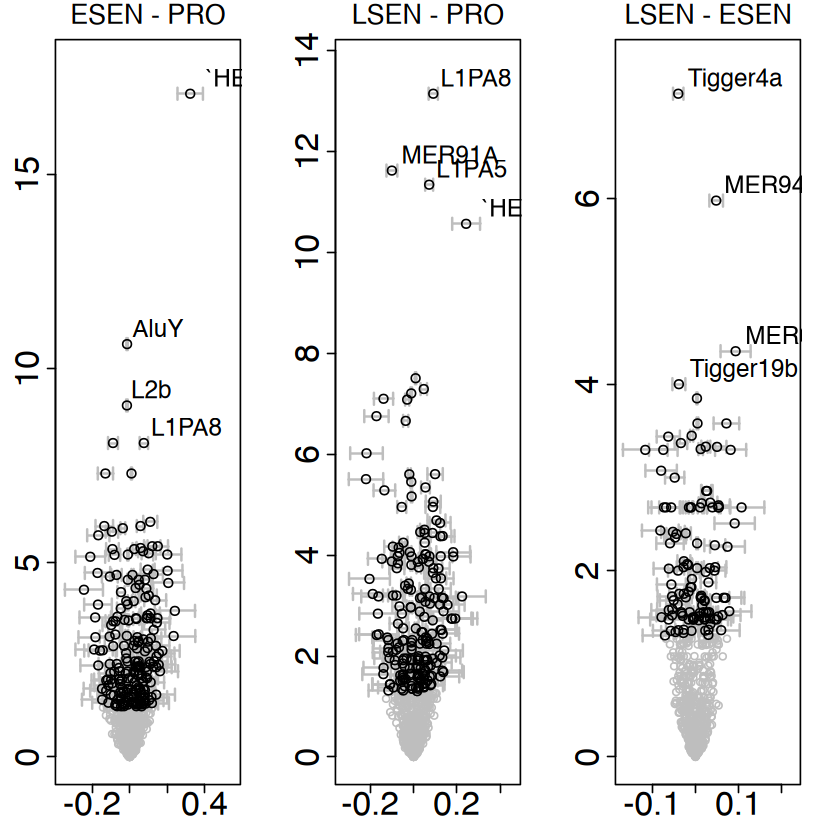

In [129]:
# ── Significant activity volcano plots ─────────────────
old_par <- par(no.readonly = TRUE)

par(
  mfrow = c(1, 3),
  mar   = c(3.5, 3.5, 2.5, 2.5)
)

plot_signif_subfams(
  res        = signif_ESEN_vs_PRO,
  alpha      = 0.05,
  main       = "ESEN - PRO",
  n_label    = 4,
  n_subplots = 3,
  idx        = 1
)

plot_signif_subfams(
  res        = signif_LSEN_vs_PRO,
  alpha      = 0.05,
  main       = "LSEN - PRO",
  n_label    = 4,
  n_subplots = 3,
  idx        = 2
)

plot_signif_subfams(
  res        = signif_LSEN_vs_ESEN,
  alpha      = 0.05,
  main       = "LSEN - ESEN",
  n_label    = 4,
  n_subplots = 3,
  idx        = 3
)

par(old_par)

**Output note.** These plots test whether TE-subfamily activity coefficients differ between senescence states, with positive coefficients pointing toward the first condition in the contrast.

### ── 8.4 - Combined all-TE contrast summary ──


The Section 7 ranking and activity-score plots are compact summaries and only show the strongest `top_k` TE-subfamily shifts. The table below is the central all-TE cis-regulatory change interpretation table: 
for every TE subfamily, mean activity across samples in the condition `PRO`, `ESEN`, and `LSEN` are calculated,
joins adjusted p-values from the three pairwise significance fits,
 and assigns a threshold-based trend class.

statistical significance is still controlled separately by `SIGNIF_ALPHA`.

In [130]:
# ── Global TE summary thresholds ───────────────────────
TE_DELTA_THRESHOLD <- 0.03
SIGNIF_ALPHA <- 0.05

**Classification note.** The all-TE summary assigns each TE subfamily to a simple senescence trend class based on its mean activity across `PRO`, `ESEN`, and `LSEN`.

A TE subfamily is only assigned to a directional class when the relevant activity change is at least `TE_DELTA_THRESHOLD`. Otherwise it remains `flat_or_noisy`. If multiple labels could match, assignment prioritises monotonic `increasing`/`decreasing`, then peak classes, then drop classes.

The classes mean:

- `increasing`: activity increases from `PRO` to `ESEN` and again from `ESEN` to `LSEN`.

- `decreasing`: activity decreases from `PRO` to `ESEN` and again from `ESEN` to `LSEN`.

- `pol_peak`: activity is higher in `PRO` than in both `ESEN` and `LSEN` by at least `TE_DELTA_THRESHOLD`.

- `esen_peak`: activity is higher in `ESEN` than in both `PRO` and `LSEN` by at least `TE_DELTA_THRESHOLD`.

- `lsen_peak`: activity is higher in `LSEN` than in both `PRO` and `ESEN` by at least `TE_DELTA_THRESHOLD`.

- `pol_drop`: activity is lower in `PRO` than in both `ESEN` and `LSEN` by at least `TE_DELTA_THRESHOLD`.

- `esen_drop`: activity is lower in `ESEN` than in both `PRO` and `LSEN` by at least `TE_DELTA_THRESHOLD`.

- `lsen_drop`: activity is lower in `LSEN` than in both `PRO` and `ESEN` by at least `TE_DELTA_THRESHOLD`.

- `flat_or_noisy`: no pairwise change is large enough to pass `TE_DELTA_THRESHOLD`, or the pattern is not cleanly assigned.

In [131]:
# ── Combined all-TE contrast summary ───────────────────
te_sample_groups <- list(
  PRO  = samples_PRO,
  ESEN = samples_ESEN,
  LSEN = samples_LSEN
)

te_contrasts <- list(
  ESEN_vs_PRO  = list(treatment = "ESEN", control = "PRO"),
  LSEN_vs_PRO  = list(treatment = "LSEN", control = "PRO"),
  LSEN_vs_ESEN = list(treatment = "LSEN", control = "ESEN")
)

te_signif_results <- list(
  ESEN_vs_PRO  = signif_ESEN_vs_PRO,
  LSEN_vs_PRO  = signif_LSEN_vs_PRO,
  LSEN_vs_ESEN = signif_LSEN_vs_ESEN
)

te_contrast_summary <- build_te_contrast_summary(
  activity_scores = A,
  sample_groups = te_sample_groups,
  contrasts = te_contrasts,
  signif_results = te_signif_results,
  delta_threshold = TE_DELTA_THRESHOLD,
  signif_alpha = SIGNIF_ALPHA
)

saved_te_contrast_summary <- write_result_object(
  input_dir = results_dir,
  name = "te_contrast_summary",
  object = te_contrast_summary,
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE
)

trend_class_counts <- as.data.frame(table(te_contrast_summary$trend_class), stringsAsFactors = FALSE)
colnames(trend_class_counts) <- c("trend_class", "n_te_subfamilies")
trend_class_counts <- trend_class_counts[order(-trend_class_counts$n_te_subfamilies), ]

print(trend_class_counts, row.names = FALSE)
saved_te_contrast_summary


   trend_class n_te_subfamilies
 flat_or_noisy              711
      pol_drop               34
      pol_peak               12
     esen_peak                6
    increasing                1


name,format,path
<chr>,<chr>,<chr>
te_contrast_summary,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/te_contrast_summary.tsv


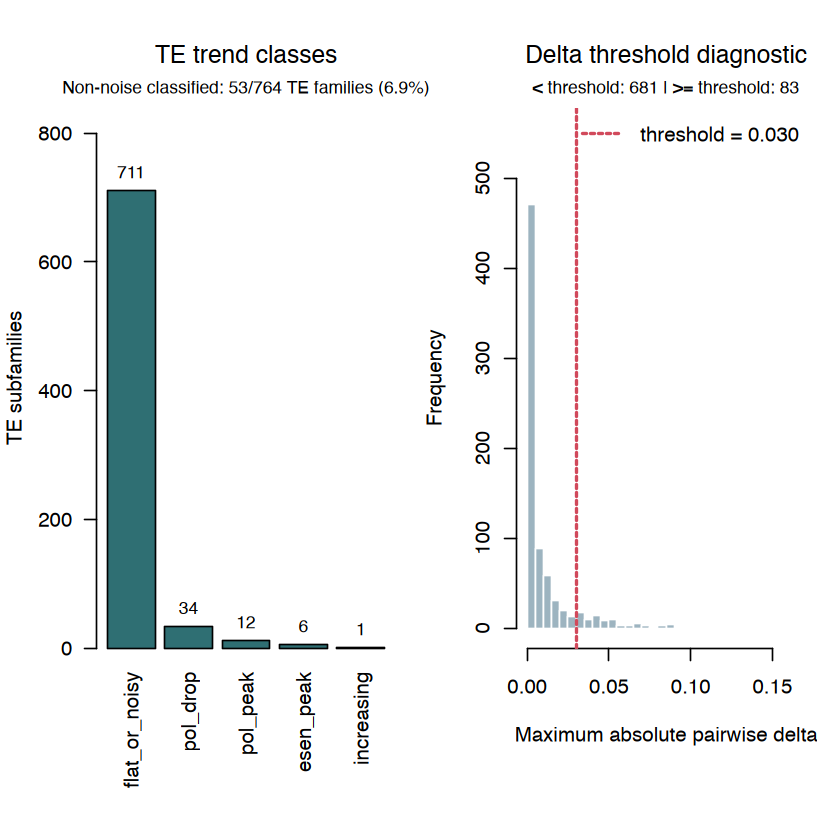

In [132]:
plot_te_trend_summary(
  te_contrast_summary,
  delta_threshold = TE_DELTA_THRESHOLD)

The left plot shows how many TE subfamilies fall into each trend class. The subtitle reports the fraction of TE families that are classified as non-noise, meaning all classes except `flat_or_noisy`.

The right plot is a threshold diagnostic. It shows the distribution of `max_abs_delta`, the strongest absolute pairwise activity shift observed for each TE subfamily. The dashed red line marks `TE_DELTA_THRESHOLD`. The summary above the plot reports how many TE families fall below the threshold and how many are at or above it.

**Interpretation note.** The trend class is an effect-size classification, not a significance test. Statistical support is stored separately in the adjusted p-value columns and in `n_significant_contrasts`. The highest-confidence TE candidates are therefore those with a non-noise trend class, a sufficiently large delta, and significant contrast support.

**Output note.** Trend classes are threshold-dependent, so `TE_DELTA_THRESHOLD` should be revisited after inspecting the delta distribution. A large `flat_or_noisy` group is expected; TE subfamilies with both clear trend classes and significant contrast support are the higher-confidence candidates for biological follow-up.


---

## 9 · Target gene matrix

In [133]:
# ── Preprocessed object for target-matrix calculations ──
preprocessed <- list(E_centered = E_centered, N = N_filtered)

`getTargetMatrix()` estimates which genes depend most strongly on each TE subfamily by computationally silencing TE subfamilies in the N matrix and measuring the loss in prediction accuracy.

For this TE-Seq dataset, the target matrices are calculated separately for the three senescence contrasts so their gene-level dependency patterns can be compared.

### ── 9.1 - ESEN vs PRO target gene matrix ──

In [134]:
# ── ESEN vs PRO target gene matrix ─────────────────────
target_genes_ESEN_vs_PRO <- getTargetMatrix(signif_ESEN_vs_PRO, preprocessed)

### ── 9.2 - LSEN vs PRO target gene matrix ──

In [135]:
# ── LSEN vs PRO target gene matrix ─────────────────────
target_genes_LSEN_vs_PRO <- getTargetMatrix(signif_LSEN_vs_PRO, preprocessed)

### ── 9.3 - LSEN vs ESEN target gene matrix ──

In [136]:
# ── LSEN vs ESEN target gene matrix ────────────────────
target_genes_LSEN_vs_ESEN <- getTargetMatrix(signif_LSEN_vs_ESEN, preprocessed)

### ── 9.4 - Combined target-gene summary ──

In [137]:
# ── Combined target-gene summary for top delta TEs ─────
target_matrices <- list(
  ESEN_vs_PRO  = target_genes_ESEN_vs_PRO,
  LSEN_vs_PRO  = target_genes_LSEN_vs_PRO,
  LSEN_vs_ESEN = target_genes_LSEN_vs_ESEN
)

delta_tables <- list(
  ESEN_vs_PRO  = delta_activity_ESEN_vs_PRO,
  LSEN_vs_PRO  = delta_activity_LSEN_vs_PRO,
  LSEN_vs_ESEN = delta_activity_LSEN_vs_ESEN
)

top_delta_tes <- vapply(names(delta_tables), function(contrast) {
  available_tes <- delta_tables[[contrast]]$te_subfamily[
    delta_tables[[contrast]]$te_subfamily %in% colnames(target_matrices[[contrast]])
  ]
  if (length(available_tes) == 0L) {
    stop(sprintf("No delta TE is available in target matrix columns for %s.", contrast), call. = FALSE)
  }
  available_tes[1]
}, character(1))

contrast_gene_stats <- lapply(names(target_matrices), function(contrast) {
  top_te <- top_delta_tes[[contrast]]
  scores <- sort(target_matrices[[contrast]][, top_te], decreasing = TRUE)
  ranks <- rank(-scores, ties.method = "min")
  list(top_te = top_te, scores = scores, ranks = ranks)
})
names(contrast_gene_stats) <- names(target_matrices)

candidate_genes <- Reduce(
  union,
  lapply(contrast_gene_stats, function(x) names(x$scores)[seq_len(min(20, length(x$scores)))])
)

target_summary <- data.frame(
  ensembl_gene_id = candidate_genes,
  hgnc_symbol = unname(ensembl_to_symbol[candidate_genes]),
  stringsAsFactors = FALSE
)

for (contrast in names(contrast_gene_stats)) {
  target_summary[[paste0(contrast, "_top_te")]] <- contrast_gene_stats[[contrast]]$top_te
  target_summary[[paste0(contrast, "_score")]] <- unname(contrast_gene_stats[[contrast]]$scores[candidate_genes])
  target_summary[[paste0(contrast, "_rank")]] <- unname(contrast_gene_stats[[contrast]]$ranks[candidate_genes])
}

score_cols <- grep("_score$", colnames(target_summary), value = TRUE)
rank_cols <- grep("_rank$", colnames(target_summary), value = TRUE)
target_summary$mean_score <- rowMeans(target_summary[, score_cols], na.rm = TRUE)
target_summary$n_top20_contrasts <- rowSums(target_summary[, rank_cols, drop = FALSE] <= 20, na.rm = TRUE)

target_summary <- target_summary[
  order(
    target_summary$n_top20_contrasts,
    target_summary$mean_score,
    decreasing = TRUE
  ),
]

cat("
Combined target-gene summary for top delta TE per contrast:
")
print(target_summary)

top_delta_tes


Combined target-gene summary for top delta TE per contrast:
   ensembl_gene_id     hgnc_symbol ESEN_vs_PRO_top_te ESEN_vs_PRO_score
1  ENSG00000138642           HERC6        HERV4_I-int        20.3529076
3  ENSG00000174718           RESF1        HERV4_I-int        14.3905435
4  ENSG00000164647          STEAP1        HERV4_I-int        11.4744644
5  ENSG00000164796           CSMD3        HERV4_I-int        11.4323494
11 ENSG00000174799          CEP135        HERV4_I-int         4.2637966
6  ENSG00000106560          GIMAP2        HERV4_I-int         7.1224842
13 ENSG00000157214          STEAP2        HERV4_I-int         3.5386166
10 ENSG00000165359          INTS6L        HERV4_I-int         4.6055373
9  ENSG00000162654            GBP4        HERV4_I-int         4.6770620
15 ENSG00000140519            RHCG        HERV4_I-int         3.3997667
16 ENSG00000090989           EXOC1        HERV4_I-int         3.3322999
2  ENSG00000138646           HERC5        HERV4_I-int        17.5264124
21 

ESEN_vs_PRO     LSEN_vs_PRO    LSEN_vs_ESEN 
  "HERV4_I-int" "MamGypsy2-LTR"   "HERV4_I-int"

In [138]:
# ── Save full target-gene matrices ─────────────────────
if (!exists("target_matrices") || length(target_matrices) == 0L) {
  stop("target_matrices must be a non-empty named list before export.", call. = FALSE)
}

target_matrix_names <- names(target_matrices)
if (is.null(target_matrix_names) || any(!nzchar(target_matrix_names))) {
  stop("target_matrices must be named before export.", call. = FALSE)
}

saved_target_gene_matrices <- do.call(
  rbind,
  lapply(target_matrix_names, function(contrast) {
    write_result_object(
      input_dir = results_dir,
      name = paste0("target_gene_matrix_", contrast),
      object = target_matrices[[contrast]],
      write_tsv = TRUE,
      write_rds = FALSE,
      overwrite = TRUE
    )
  })
)

saved_target_summary <- write_result_object(
  input_dir = results_dir,
  name = "target_summary",
  object = target_summary,
  write_tsv = TRUE,
  write_rds = FALSE,
  overwrite = TRUE
)

saved_target_results <- rbind(saved_target_gene_matrices, saved_target_summary)
saved_target_results

name,format,path
<chr>,<chr>,<chr>
target_gene_matrix_ESEN_vs_PRO,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/target_gene_matrix_ESEN_vs_PRO.tsv
target_gene_matrix_LSEN_vs_PRO,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/target_gene_matrix_LSEN_vs_PRO.tsv
target_gene_matrix_LSEN_vs_ESEN,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/target_gene_matrix_LSEN_vs_ESEN.tsv
target_summary,tsv,/Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/target_summary.tsv


**Output note.** The combined table compares genes most affected by the top delta TE from each senescence contrast. Scores are relative target-dependency approximations, not p-values.

### ── 9.5 - Comparable heatmaps of target contributions ──

**Colour legend.** Heatmap values are row z-scores of target-dependency values, so colours are relative within each gene.

<span style="display:inline-block;width:12px;height:12px;background:#B2182B;border:1px solid #555;vertical-align:-1px;margin-right:4px;"></span> **Red:** stronger-than-average TE dependency for that gene  
<span style="display:inline-block;width:12px;height:12px;background:#FFFFFF;border:1px solid #999;vertical-align:-1px;margin-right:4px;"></span> **White:** close to that gene's average across the shown TEs  
<span style="display:inline-block;width:12px;height:12px;background:#2166AC;border:1px solid #555;vertical-align:-1px;margin-right:4px;"></span> **Blue:** weaker-than-average TE dependency for that gene

Saved: /Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/figures/target_matrix_full_ESEN_vs_PRO.pdf

Saved: /Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/figures/target_matrix_full_LSEN_vs_PRO.pdf



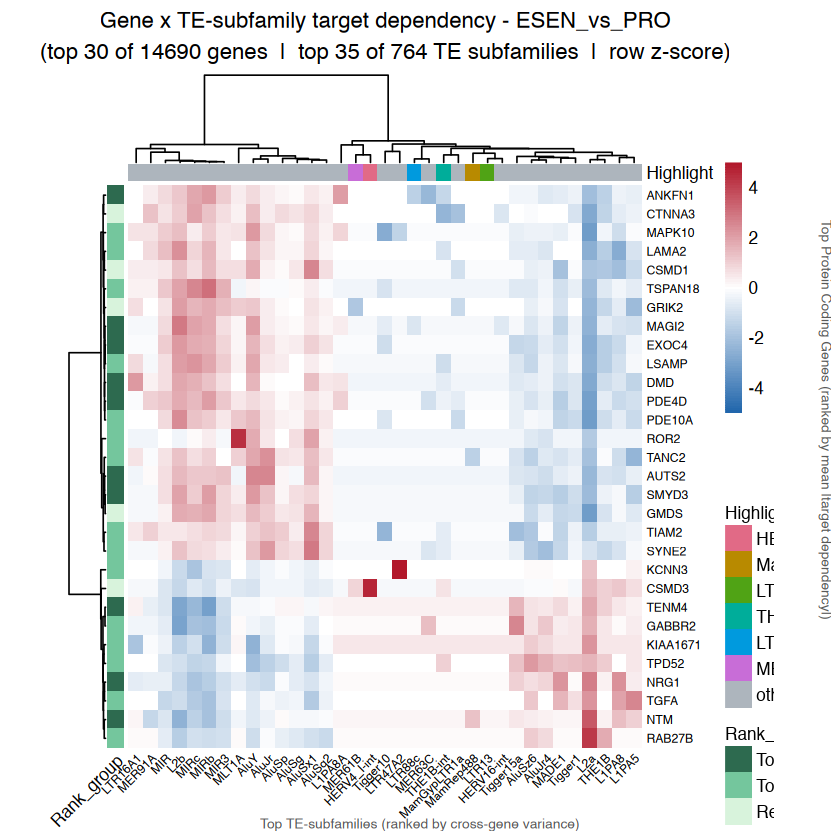

Saved: /Users/vinzent/craTEs/results/results_E_Senescene_TE_Seq_raw_N_c_100_Hg38_craTEs/figures/target_matrix_full_LSEN_vs_ESEN.pdf



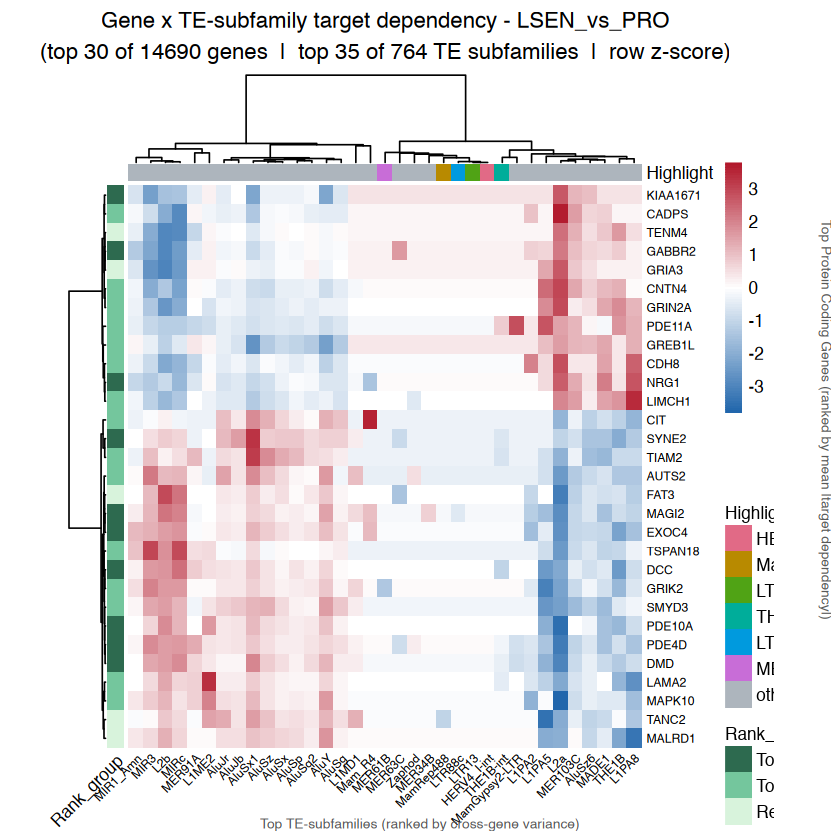

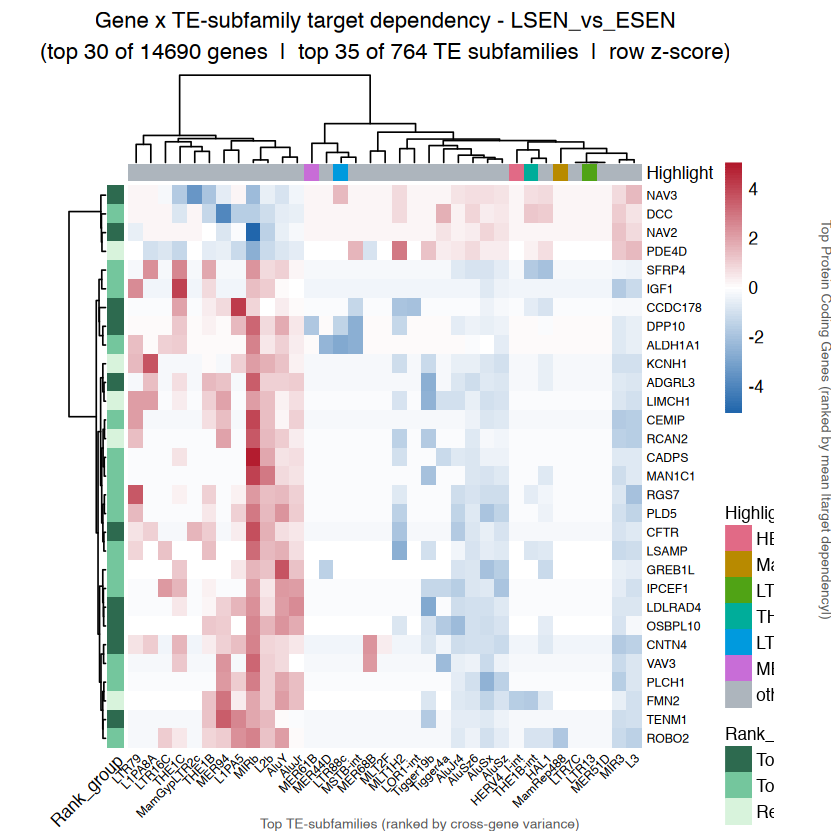

In [139]:
# ── Comparable target contribution heatmaps ────────────
plot_target_matrix_full(
  target_mat_raw   = target_genes_ESEN_vs_PRO,
  ensembl_to_symbol = ensembl_to_symbol,
  condition_label  = "ESEN_vs_PRO",
  top_n_genes      = 30,
  top_n_TE         = 30,
  highlight_TEs    = tes_to_plot,
  out_dir          = figures_dir,
  show = TRUE
)

plot_target_matrix_full(
  target_mat_raw   = target_genes_LSEN_vs_PRO,
  ensembl_to_symbol = ensembl_to_symbol,
  condition_label  = "LSEN_vs_PRO",
  top_n_genes      = 30,
  top_n_TE         = 30,
  highlight_TEs    = tes_to_plot,
  out_dir          = figures_dir,
  show = TRUE
)

plot_target_matrix_full(
  target_mat_raw   = target_genes_LSEN_vs_ESEN,
  ensembl_to_symbol = ensembl_to_symbol,
  condition_label  = "LSEN_vs_ESEN",
  top_n_genes      = 30,
  top_n_TE         = 30,
  highlight_TEs    = tes_to_plot,
  out_dir          = figures_dir,
  show = TRUE
)

## Result comparison

Now we want to compare our findings to findings with other results with other N matrices. 